In [ ]:


 import pandas as pd

files = [
    "/content/thalassimia.xlsx",
    "/content/alphanorm.csv",
    "/content/westbengal.csv",
    "/content/Thalassemia_Bangladesh_dataset.csv",
    "/content/twoalphas.csv",
    "/content/IDA_BTT.csv"
]

dataframes = {}

for file_path in files:
    file_name = file_path.split('/')[-1].split('.')[0]
    df_name = f"{file_name}_df"
    if file_path.endswith('.csv'):
        dataframes[df_name] = pd.read_csv(file_path)
    elif file_path.endswith('.xlsx'):
        dataframes[df_name] = pd.read_excel(file_path)

for df_name, df in dataframes.items():
    print(f"--- Head of {df_name} ---")
    print(df.head())
    print("\n")

--- Head of thalassimia_df ---
   ID  Gender   Age   MCV   HBG   MCH  RBC   S HBA2   HBA  HBF  Iron  \
0   1       1  30.0  63.9  11.5  20.4  NaN NaN  5.8  92.1  1.7   9.6   
1   2       0  14.0  62.0   7.0  17.8  NaN NaN  2.2  97.8  NaN   NaN   
2   3       1  29.0  72.0  16.8  24.1  NaN NaN  3.5  96.3  NaN   NaN   
3   4       0  27.0  61.0   8.5  24.6  NaN NaN  2.3  97.6  NaN   0.1   
4   5       1   2.0  53.6   8.9  17.0  NaN NaN  2.5  97.5  NaN   NaN   

   Unnamed: 12  Unnamed: 13  Unnamed: 14  Unnamed: 15 Unnamed: 16  Unnamed: 17  
0          NaN          NaN          NaN          NaN         NaN          NaN  
1          NaN          NaN          NaN          NaN         NaN          NaN  
2          NaN          NaN          NaN          NaN         NaN          NaN  
3          NaN          NaN          NaN          NaN         NaN          NaN  
4          NaN          NaN          NaN          NaN         NaN          NaN  


--- Head of alphanorm_df ---
      sex    hb   p

In [ ]:
dataframes_to_check = ['twoalphas_df', 'alphanorm_df']

for df_name in dataframes_to_check:
    if df_name in dataframes and 'phenotype' in dataframes[df_name].columns:
        print(f"--- Prevalence of 'phenotype' in {df_name} ---")
        phenotype_prevalence = dataframes[df_name]['phenotype'].value_counts()
        print(phenotype_prevalence)
        print("\n")
    else:
        print(f"The '{df_name}' dataframe or 'phenotype' column was not found.")


--- Prevalence of 'phenotype' in twoalphas_df ---
phenotype
silent carrier    105
alpha trait        42
Name: count, dtype: int64


--- Prevalence of 'phenotype' in alphanorm_df ---
phenotype
alpha carrier    148
normal            55
Name: count, dtype: int64




In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

def get_stats(group):
    res = {'N': len(group)}
    for p in params:
        data = group[p].dropna()
        if len(data) < 2:
            res.update({f'{p}_M': 'N/A', f'{p}_CI': 'N/A'})
            continue

        m = np.mean(data)
        se = stats.sem(data)
        ci = stats.t.interval(0.95, len(data)-1, loc=m, scale=se)
        res[f'{p}_M'] = f"{m:.2f}"
        res[f'{p}_CI'] = f"({ci[0]:.2f}-{ci[1]:.2f})"
    return pd.Series(res)

params = ['hb', 'pcv', 'rbc', 'wbc', 'plt'] # Add more as needed
dfs = ['alphanorm_df', 'twoalphas_df']

for name in dfs:
    df = dataframes[name]
    print(f"\n--- Analysis for {name} ---")

    # 1. Generate the Mean and CI Table
    main_stats = df.groupby(['sex', 'phenotype'], group_keys=False).apply(get_stats, include_groups=False)
    display(main_stats)

    # 2. Calculate P-Values (Comparing phenotypes within each sex)
    print(f"P-values for {name}:")
    for sex in df['sex'].unique():
        sub = df[df['sex'] == sex]
        phenos = sub['phenotype'].unique()
        if len(phenos) == 2:
            g1 = sub[sub['phenotype'] == phenos[0]]
            g2 = sub[sub['phenotype'] == phenos[1]]
            print(f"\n{sex.upper()} ({phenos[0]} vs {phenos[1]}):")
            for p in params:
                p_val = stats.ttest_ind(g1[p].dropna(), g2[p].dropna()).pvalue
                sig = "*" if p_val < 0.05 else ""
                print(f"  {p}: {p_val:.4f} {sig}")


--- Analysis for alphanorm_df ---


N   hb_M          hb_CI  pcv_M         pcv_CI rbc_M  \
sex    phenotype                                                             
female alpha carrier  65  11.61  (11.28-11.95)  35.74  (34.89-36.59)  4.93   
       normal         26  11.33  (10.73-11.93)  34.55  (32.92-36.18)  4.97   
male   alpha carrier  83  12.53  (12.11-12.95)  37.50  (36.28-38.73)  5.10   
       normal         29  12.74  (12.04-13.43)  38.31  (36.49-40.14)  5.28   

                           rbc_CI wbc_M        wbc_CI   plt_M           plt_CI  
sex    phenotype                                                                
female alpha carrier  (4.81-5.06)  9.00   (8.47-9.53)  324.72  (301.57-347.88)  
       normal         (4.77-5.17)  8.90   (8.17-9.63)  372.55  (301.46-443.63)  
male   alpha carrier  (4.96-5.25)  9.18   (8.50-9.87)  329.25  (304.90-353.61)  
       normal         (5.07-5.49)  9.89  (8.98-10.80)  293.68  (261.68-325.68)

P-values for alphanorm_df:

FEMALE (alpha carrier vs normal):
  hb: 0.3772 
  pcv: 0.1600 
  rbc: 0.7377 
  wbc: 0.8381 
  plt: 0.0957 

MALE (alpha carrier vs normal):
  hb: 0.6122 
  pcv: 0.4898 
  rbc: 0.2041 
  wbc: 0.2719 
  plt: 0.1200 

--- Analysis for twoalphas_df ---


N   hb_M          hb_CI  pcv_M         pcv_CI rbc_M  \
sex    phenotype                                                              
female alpha trait     22  10.60  (10.16-11.04)  33.07  (31.96-34.17)  5.24   
       silent carrier  50  11.50  (11.09-11.90)  35.37  (34.30-36.44)  4.97   
male   alpha trait     20  11.02  (10.30-11.73)  33.18  (31.16-35.20)  5.14   
       silent carrier  55  12.16  (11.70-12.61)  36.34  (35.17-37.50)  5.15   

                            rbc_CI wbc_M        wbc_CI   plt_M  \
sex    phenotype                                                 
female alpha trait     (5.01-5.47)  8.98   (8.22-9.75)  331.14   
       silent carrier  (4.82-5.11)  9.00   (8.32-9.68)  339.80   
male   alpha trait     (4.69-5.59)  8.84  (7.31-10.37)  394.85   
       silent carrier  (4.99-5.31)  9.90  (9.09-10.71)  328.17   

                                plt_CI  
sex    phenotype                        
female alpha trait     (283.33-378.94)  
       silent carrier  (313.35-366.25)  
male   alpha trait     (332.52-457.17)  
       silent carrier  (302.87-353.48)

P-values for twoalphas_df:

FEMALE (alpha trait vs silent carrier):
  hb: 0.0088 *
  pcv: 0.0105 *
  rbc: 0.0434 *
  wbc: 0.9758 
  plt: 0.7301 

MALE (alpha trait vs silent carrier):
  hb: 0.0093 *
  pcv: 0.0064 *
  rbc: 0.9880 
  wbc: 0.1902 
  plt: 0.0178 *


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

def get_stats(group, params):
    res = {'N': len(group)}
    for p in params:
        data = group[p].dropna()
        if len(data) >= 2:
            m = np.mean(data)
            se = stats.sem(data)
            ci = stats.t.interval(0.95, len(data)-1, loc=m, scale=se)
            res[f'{p}_M'] = f"{m:.2f}"
            res[f'{p}_CI'] = f"({ci[0]:.2f}-{ci[1]:.2f})"
            res[f'{p}_Min'] = f"{np.min(data):.2f}"
            res[f'{p}_Max'] = f"{np.max(data):.2f}"
        elif len(data) == 1:
            res[f'{p}_M'] = f"{data.iloc[0]:.2f}"
            res[f'{p}_CI'] = "N/A"
            res[f'{p}_Min'] = f"{data.iloc[0]:.2f}"
            res[f'{p}_Max'] = f"{data.iloc[0]:.2f}"
        else:
            res[f'{p}_M'] = "N/A"
            res[f'{p}_CI'] = "N/A"
            res[f'{p}_Min'] = "N/A"
            res[f'{p}_Max'] = "N/A"
    return pd.Series(res)

# Specific parameters for IDA_BTT_df
params = ['Hb', 'CBC_MCV', 'CBC_MCH', 'CBC_RBC', 'Platelets', 'CBC_RDW', 'CBC_HCT']
name = 'IDA_BTT_df'

if name in dataframes:
    df = dataframes[name]
    print(f"\n--- Analysis for {name} ---")
    main_stats = df.groupby(['Gender', 'Class'], group_keys=False).apply(lambda x: get_stats(x, params), include_groups=False)
    display(main_stats)

    # 2. Calculate P-Values (Comparing classes within each gender)
    print(f"P-values for {name} (Comparing Class 0 vs Class 1):")
    for gender in df['Gender'].unique():
        sub = df[df['Gender'] == gender]
        classes = sub['Class'].unique()

        if len(classes) == 2:
            g1 = sub[sub['Class'] == classes[0]]
            g2 = sub[sub['Class'] == classes[1]]

            gender_label = "MALE" if gender == 0 else "FEMALE"
            print(f"\n{gender_label} (Class {classes[0]} vs Class {classes[1]}):")

            for p in params:
                d1 = g1[p].dropna()
                d2 = g2[p].dropna()
                if len(d1) > 1 and len(d2) > 1:
                    p_val = stats.ttest_ind(d1, d2).pvalue
                    sig = "*" if p_val < 0.05 else ""
                    print(f"  {p}: {p_val:.4f} {sig}")
                else:
                    print(f"  {p}: Insufficient data")
else:
    print(f"{name} not found in dataframes dictionary.")



--- Analysis for IDA_BTT_df ---


N   Hb_M         Hb_CI Hb_Min Hb_Max CBC_MCV_M     CBC_MCV_CI  \
Gender Class                                                                    
0      0      125   7.13   (6.79-7.47)   2.30  12.00     72.78  (71.44-74.12)   
       1       28  10.93  (9.78-12.08)   6.60  15.80     77.26  (73.70-80.83)   
1      0       80   6.99   (6.51-7.47)   2.20  12.90     73.20  (71.38-75.03)   
       1       17   9.38  (8.23-10.54)   3.60  12.80     73.48  (65.90-81.06)   

             CBC_MCV_Min CBC_MCV_Max CBC_MCH_M  ... Platelets_Min  \
Gender Class                                    ...                 
0      0           53.00       98.30     45.48  ...         50.00   
       1           46.00       91.90     26.90  ...         22.00   
1      0           56.00       98.30     25.98  ...         31.00   
       1           54.00      113.30     24.28  ...         78.00   

             Platelets_Max CBC_RDW_M     CBC_RDW_CI CBC_RDW_Min CBC_RDW_Max  \
Gender Class                                                                  
0      0            752.00     24.03  (22.49-25.57)       14.60       48.50   
       1           2112.00      5.67    (2.01-9.33)        0.00       30.50   
1      0            799.00     23.47  (21.44-25.50)       13.23       49.60   
       1            653.00      8.39   (1.49-15.28)        0.00       47.30   

             CBC_HCT_M     CBC_HCT_CI CBC_HCT_Min CBC_HCT_Max  
Gender Class                                                   
0      0         19.61  (18.55-20.66)        2.30       37.00  
       1         31.92  (28.31-35.54)       18.02       49.00  
1      0         19.96  (18.53-21.39)        8.40       36.47  
       1         26.50  (21.97-31.02)        3.40       40.00  

[4 rows x 29 columns]

P-values for IDA_BTT_df (Comparing Class 0 vs Class 1):

FEMALE (Class 1 vs Class 0):
  Hb: 0.0001 *
  CBC_MCV: 0.9151 
  CBC_MCH: 0.0398 *
  CBC_RBC: 0.0000 *
  Platelets: 0.8935 
  CBC_RDW: 0.0000 *
  CBC_HCT: 0.0006 *

MALE (Class 0 vs Class 1):
  Hb: 0.0000 *
  CBC_MCV: 0.0075 *
  CBC_MCH: 0.6454 
  CBC_RBC: 0.0000 *
  Platelets: 0.3034 
  CBC_RDW: 0.0000 *
  CBC_HCT: 0.0000 *



--- Correlation Analysis for alphanorm_df ---

Correlation Matrix for alpha carrier (alphanorm_df):
        hb   pcv   rbc   mcv   mch  mchc   rdw   wbc   plt
hb    1.00  0.87  0.41  0.61  0.59  0.35 -0.57 -0.04 -0.33
pcv   0.87  1.00  0.37  0.60  0.48  0.13 -0.55 -0.05 -0.39
rbc   0.41  0.37  1.00 -0.35 -0.39 -0.19  0.11  0.21  0.11
mcv   0.61  0.60 -0.35  1.00  0.85  0.29 -0.65 -0.22 -0.46
mch   0.59  0.48 -0.39  0.85  1.00  0.52 -0.64 -0.18 -0.44
mchc  0.35  0.13 -0.19  0.29  0.52  1.00 -0.34 -0.07 -0.14
rdw  -0.57 -0.55  0.11 -0.65 -0.64 -0.34  1.00  0.16  0.49
wbc  -0.04 -0.05  0.21 -0.22 -0.18 -0.07  0.16  1.00  0.47
plt  -0.33 -0.39  0.11 -0.46 -0.44 -0.14  0.49  0.47  1.00


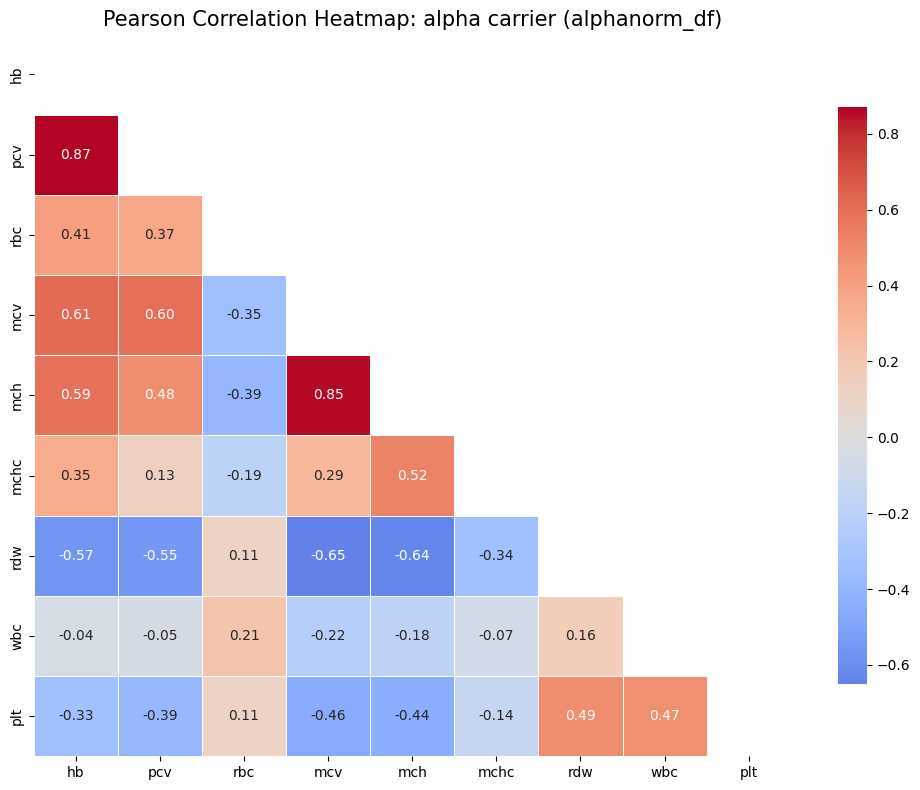


Correlation Matrix for normal (alphanorm_df):
        hb   pcv   rbc   mcv   mch  mchc   rdw   wbc   plt
hb    1.00  0.90  0.31  0.77  0.75  0.38 -0.59 -0.05 -0.42
pcv   0.90  1.00  0.23  0.78  0.71  0.20 -0.57 -0.00 -0.46
rbc   0.31  0.23  1.00 -0.32 -0.38 -0.36 -0.04  0.18  0.14
mcv   0.77  0.78 -0.32  1.00  0.96  0.44 -0.59 -0.15 -0.54
mch   0.75  0.71 -0.38  0.96  1.00  0.66 -0.53 -0.16 -0.47
mchc  0.38  0.20 -0.36  0.44  0.66  1.00 -0.13 -0.14 -0.07
rdw  -0.59 -0.57 -0.04 -0.59 -0.53 -0.13  1.00  0.04  0.68
wbc  -0.05 -0.00  0.18 -0.15 -0.16 -0.14  0.04  1.00  0.14
plt  -0.42 -0.46  0.14 -0.54 -0.47 -0.07  0.68  0.14  1.00


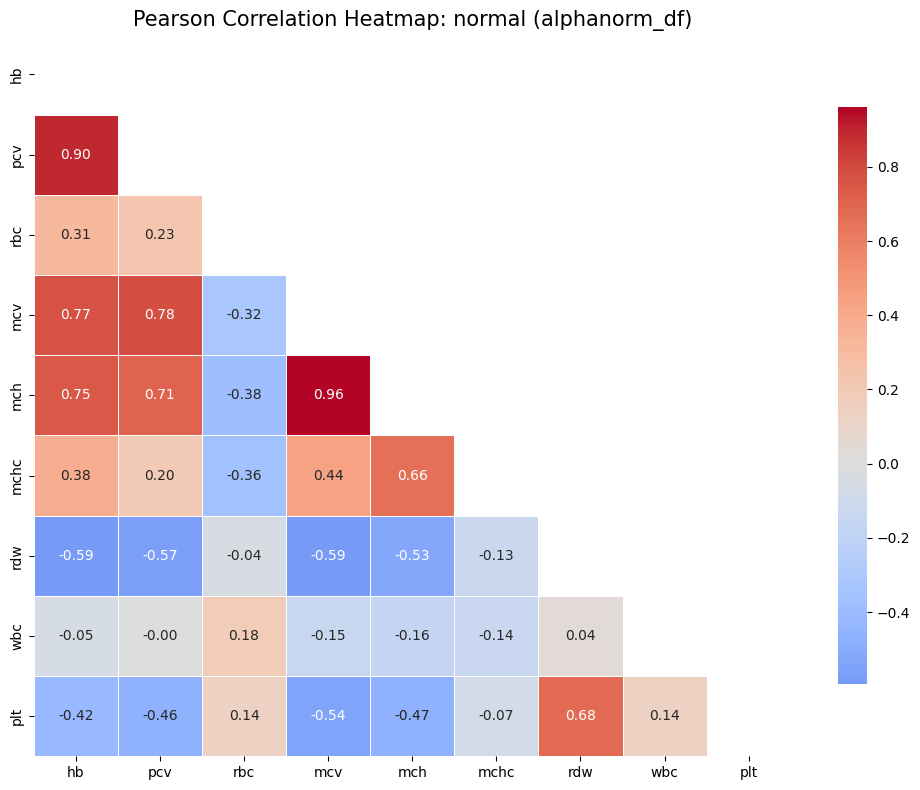


--- Correlation Analysis for twoalphas_df ---

Correlation Matrix for alpha trait (twoalphas_df):
        hb   pcv   rbc   mcv   mch  mchc   rdw   wbc   plt
hb    1.00  0.69  0.56  0.13  0.24  0.24 -0.35 -0.11 -0.16
pcv   0.69  1.00  0.44  0.14  0.10 -0.10 -0.50  0.06 -0.27
rbc   0.56  0.44  1.00 -0.57 -0.35 -0.21  0.00  0.32 -0.04
mcv   0.13  0.14 -0.57  1.00  0.78  0.16 -0.41 -0.27 -0.28
mch   0.24  0.10 -0.35  0.78  1.00  0.45 -0.38 -0.20 -0.30
mchc  0.24 -0.10 -0.21  0.16  0.45  1.00 -0.09 -0.28  0.02
rdw  -0.35 -0.50  0.00 -0.41 -0.38 -0.09  1.00  0.01  0.25
wbc  -0.11  0.06  0.32 -0.27 -0.20 -0.28  0.01  1.00  0.41
plt  -0.16 -0.27 -0.04 -0.28 -0.30  0.02  0.25  0.41  1.00


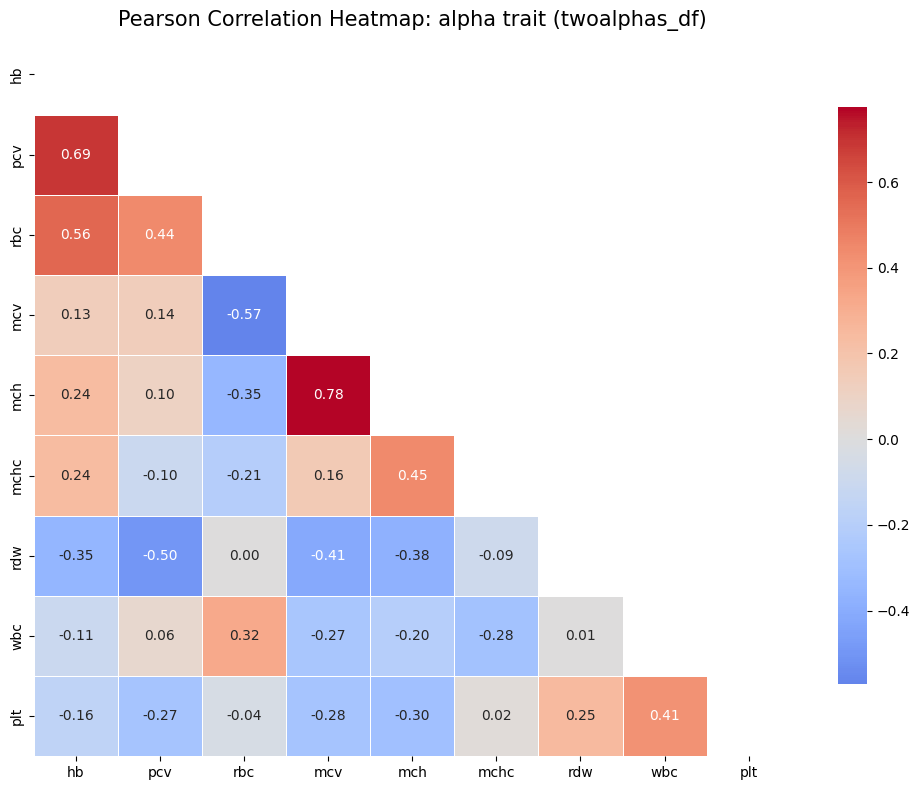


Correlation Matrix for silent carrier (twoalphas_df):
        hb   pcv   rbc   mcv   mch  mchc   rdw   wbc   plt
hb    1.00  0.83  0.55  0.59  0.63  0.27 -0.58  0.01 -0.15
pcv   0.83  1.00  0.45  0.59  0.54  0.07 -0.49 -0.01 -0.16
rbc   0.55  0.45  1.00 -0.27 -0.29 -0.08 -0.05  0.25  0.19
mcv   0.59  0.59 -0.27  1.00  0.93  0.09 -0.60 -0.26 -0.33
mch   0.63  0.54 -0.29  0.93  1.00  0.39 -0.62 -0.21 -0.35
mchc  0.27  0.07 -0.08  0.09  0.39  1.00 -0.28  0.00 -0.19
rdw  -0.58 -0.49 -0.05 -0.60 -0.62 -0.28  1.00  0.14  0.28
wbc   0.01 -0.01  0.25 -0.26 -0.21  0.00  0.14  1.00  0.52
plt  -0.15 -0.16  0.19 -0.33 -0.35 -0.19  0.28  0.52  1.00


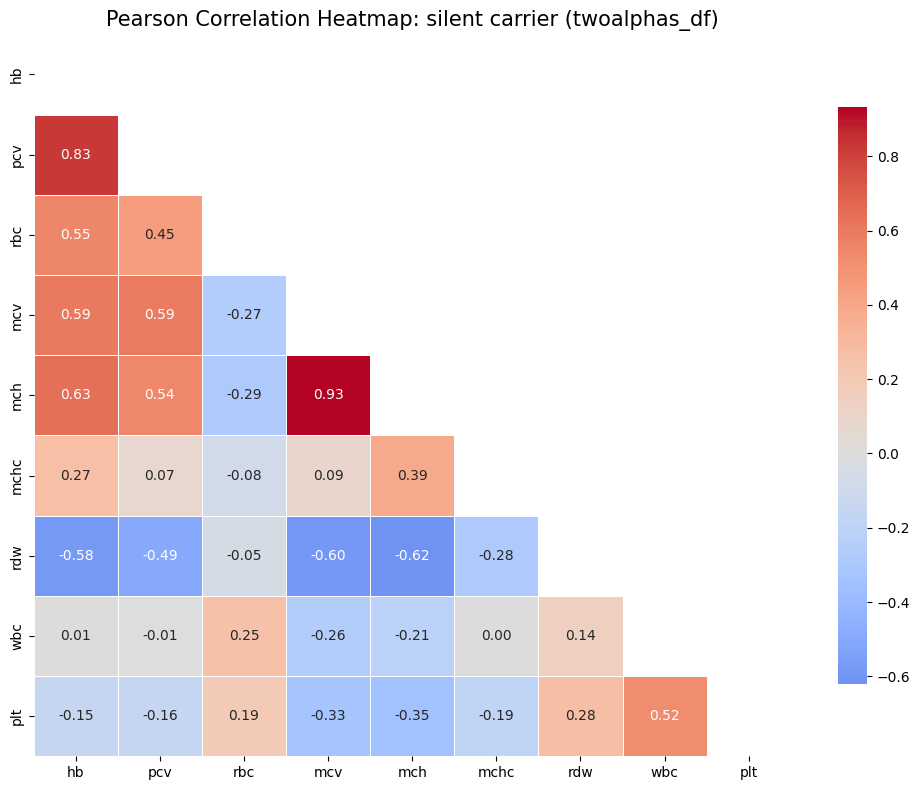

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def generate_correlation_heatmaps(df_name, df_original):
    # Parameters we care about for CBC correlation
    cbc_params = ['hb', 'pcv', 'rbc', 'mcv', 'mch', 'mchc', 'rdw', 'wbc', 'plt']

    # Ensure columns exist in the dataframe
    df = df_original.copy()
    available_params = [p for p in cbc_params if p in df.columns]

    # Define the phenotypes we want to compare
    phenotypes = df['phenotype'].unique()

    print(f"\n--- Correlation Analysis for {df_name} ---")

    for pheno in phenotypes:
        # Filter data for the specific phenotype
        subset = df[df['phenotype'] == pheno][available_params]

        if subset.empty or len(subset) < 2:
            print(f"\nSkipping {pheno}: Not enough data.")
            continue

        # Calculate Pearson Correlation
        corr_matrix = subset.corr(method='pearson')
        print(f"\nCorrelation Matrix for {pheno} ({df_name}):")
        print(corr_matrix.round(2).to_string())
        corr_matrix.round(2).to_csv(
            f"{df_name}_{pheno}_correlation_matrix.csv"
        )

        # ===== HEATMAP =====
        plt.figure(figsize=(10, 8))

        # Mask upper triangle for cleaner appearance
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

        sns.heatmap(
            corr_matrix,
            mask=mask,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            center=0,
            linewidths=.5,
            cbar_kws={"shrink": .8}
        )

        plt.title(
            f"Pearson Correlation Heatmap: {pheno} ({df_name})",
            fontsize=15
        )

        plt.tight_layout()
        plt.show()

# Execute for your Alpha datasets
for name in ['alphanorm_df', 'twoalphas_df']:
    if name in dataframes:
        generate_correlation_heatmaps(name, dataframes[name])

In [ ]:
wb_df = dataframes['westbengal_df']
normal_variants = wb_df['Diagnosis'].astype(str).str.contains('normal', case=False, na=False)
values_to_replace = wb_df.loc[normal_variants, 'Diagnosis'].unique()
wb_df['Diagnosis'] = wb_df['Diagnosis'].replace(values_to_replace, 'Normal')

In [ ]:
import re

def convert_age_to_years(age_str):
    if pd.isna(age_str) or not isinstance(age_str, str):
        return np.nan

    # Extract years and months using regex
    years = re.search(r'(\d+)\s*Yrs?', age_str)
    months = re.search(r'(\d+)\s*month', age_str)

    y = int(years.group(1)) if years else 0
    m = int(months.group(1)) if months else 0

    total_months = (y * 12) + m
    return total_months / 12.0

# Apply conversion to westbengal_df
wb_df = dataframes['westbengal_df']
wb_df['Age_Years'] = wb_df['Age'].apply(convert_age_to_years)

print("Sample of age conversion:")
display(wb_df[['Age', 'Age_Years']].head())

# Get value counts for categorical columns
columns_to_count = ['Gender', 'Jaundice', 'Diagnosis']

for col in columns_to_count:
    if col in wb_df.columns:
        print(f"\n--- Value Counts for {col} ---")
        display(wb_df[col].value_counts())
    else:
        print(f"\nColumn '{col}' not found in the dataframe.")

Sample of age conversion:


,Age,Age_Years
0,14 Yrs 11 month,14.916667
1,16 Yrs 0 month,16.000000
2,16 Yrs 2 month,16.166667
3,21 Yrs 0 month,21.000000
4,35 Yrs 3 month,35.250000



--- Value Counts for Gender ---


,count
Gender,
Female,9001
Male,4030



--- Value Counts for Jaundice ---


,count
Jaundice,
No,12992
Yes,28



--- Value Counts for Diagnosis ---


,count
Diagnosis,
Normal,11783
Beta Thalassaemia carrier,562
HbE carrier,546
HbS carrier,51
HbD carrier,25
HbE disease,20
HbE-Beta Thalassaemia,19
Beta Thalassaemia major,13
Beta trait with high foetal haemoglobin,6


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import re

def conv_age(s):
    if not isinstance(s, str): return np.nan
    y = re.search(r'(\d+)\s*Yrs?', s)
    m = re.search(r'(\d+)\s*month', s)
    return (int(y.group(1)) if y else 0) + (int(m.group(1)) if m else 0)/12

df = dataframes['westbengal_df'].copy()
df['Age_Years'] = df['Age'].apply(conv_age)
df['Diagnosis'] = df['Diagnosis'].str.strip().replace(['Normal', 'Normal ', 'Normal  '], 'Normal')
df['Age_Bracket'] = np.where(df['Age_Years'] < 18, 'Pediatric', 'Adult')

params = ['HB', 'RBC', 'MCV', 'MCH', 'MCHC', 'RDWcv', 'HbA0', 'HbA2', 'HbF']

def get_stats(group):
    # Pull metadata from the group's index name since it might be missing from columns
    age_br, gen, diag = group.name
    res = {'N': len(group)}
    base = df[(df['Diagnosis'] == 'Normal') & (df['Age_Bracket'] == age_br) & (df['Gender'] == gen)]

    for p in params:
        val = pd.to_numeric(group[p], errors='coerce').dropna()
        if len(val) >= 2:
            m = np.mean(val)
            se = stats.sem(val)
            ci = stats.t.interval(0.95, len(val)-1, loc=m, scale=se)
            res[f'{p}_M'], res[f'{p}_CI'] = f"{m:.2f}", f"({ci[0]:.2f}-{ci[1]:.2f})"
            res[f'{p}_Min'] = f"{np.min(val):.2f}"
            res[f'{p}_Max'] = f"{np.max(val):.2f}"
        elif len(val) == 1:
            res.update({f'{p}_M': f"{val.mean():.2f}", f'{p}_CI': "N/A"})
            res[f'{p}_Min'] = f"{val.iloc[0]:.2f}"
            res[f'{p}_Max'] = f"{val.iloc[0]:.2f}"
        else:
            res.update({f'{p}_M': "N/A", f'{p}_CI': "N/A"})
            res.update({f'{p}_Min': "N/A", f'{p}_Max': "N/A"})

        if diag == 'Normal':
            res[f'{p}_P'] = "-"
        else:
            norm = pd.to_numeric(base[p], errors='coerce').dropna()
            if len(val) > 1 and len(norm) > 1:
                pv = stats.ttest_ind(val, norm, equal_var=True).pvalue
                res[f'{p}_P'] = f"{pv:.4f}{'*' if pv < 0.05 else ''}"
            else:
                res[f'{p}_P'] = "N/A"
    return pd.Series(res)

output = df.groupby(['Age_Bracket', 'Gender', 'Diagnosis']).apply(get_stats)
pd.set_option('display.max_columns', None)
display(output)


/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_3955/1048489574.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this w

N   HB_M  \
Age_Bracket Gender Diagnosis                                              
Adult       Female Beta Thalassaemia carrier                 260   9.90   
                   Beta Thalassaemia major                     3   6.77   
                   Beta trait with high foetal haemoglobin     5   9.10   
                   Delta beta carrier                          1  12.40   
                   HPFH trait                                  1   9.50   
                   HbD carrier                                13  11.54   
                   HbE carrier                               258  11.05   
                   HbE disease                                10   8.95   
                   HbE-Beta Thalassaemia                       7   7.20   
                   HbS carrier                                31  10.97   
                   HbS-Beta Thalassaemia                       1   8.80   
                   Normal                                   6068  11.36   
            Male   Beta Thalassaemia carrier                 100  11.60   
                   Beta Thalassaemia major                     1   1.70   
                   HbD carrier                                 1  14.60   
                   HbE carrier                                94  12.76   
                   HbE disease                                 3   8.70   
                   HbE-Beta Thalassaemia                       3   7.20   
                   HbS carrier                                 5  13.36   
                   Normal                                   1818  13.41   
Pediatric   Female Beta Thalassaemia carrier                  98  10.48   
                   Beta Thalassaemia major                     5   5.52   
                   HbD carrier                                 9  11.77   
                   HbD disease                                 1  11.20   
                   HbE carrier                                88  11.44   
                   HbE disease                                 4   9.07   
                   HbE-Beta Thalassaemia                       3   6.50   
                   HbS carrier                                 9  11.59   
                   Normal                                   2126  11.77   
            Male   Beta Thalassaemia carrier                 104  11.09   
                   Beta Thalassaemia major                     4   5.72   
                   Beta trait with high foetal haemoglobin     1   8.90   
                   HPFH trait                                  1  10.70   
                   HbD carrier                                 2  12.60   
                   HbE carrier                               106  11.90   
                   HbE disease                                 3  10.30   
                   HbE-Beta Thalassaemia                       6   5.80   
                   HbS carrier                                 6  11.07   
                   HbS-Beta Thalassaemia                       1   6.90   
                   Normal                                   1771  12.41   

                                                                    HB_CI  \
Age_Bracket Gender Diagnosis                                                
Adult       Female Beta Thalassaemia carrier                 (9.73-10.06)   
                   Beta Thalassaemia major                    (3.76-9.77)   
                   Beta trait with high foetal haemoglobin   (7.17-11.03)   
                   Delta beta carrier                                 N/A   
                   HPFH trait                                         N/A   
                   HbD carrier                              (10.58-12.49)   
                   HbE carrier                              (10.88-11.22)   
                   HbE disease                                (8.33-9.57)   
                   HbE-Beta Thalassaemia                      (6.46-7.94)   
                   HbS carrier                              (10.5

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

df = dataframes['Thalassemia_Bangladesh_dataset_df'].copy()
df['Age_Bracket'] = np.where(df['Current_Age'] < 18, 'Pediatric', 'Adult')
params = ['MCV (fL)', 'MCH (pg)', 'RDW (%)', 'HbF_Percent (%)',
          'Transfusion_Frequency (units/month)', 'BMI (kg/m²)']

def get_bangla_stats(group):
    res = {'N': len(group)}

    for p in params:
        data = pd.to_numeric(group[p], errors='coerce').dropna()

        if len(data) >= 2:
            m = np.mean(data)
            se = stats.sem(data)
            ci = stats.t.interval(0.95, len(data)-1, loc=m, scale=se)
            res[f'{p}_Mean'] = f"{m:.2f}"
            res[f'{p}_CI'] = f"({ci[0]:.2f}-{ci[1]:.2f})"
        elif len(data) == 1:
            res[f'{p}_Mean'] = f"{data.iloc[0]:.2f}"
            res[f'{p}_CI'] = "N/A"
        else:
            res[f'{p}_Mean'] = "N/A"
            res[f'{p}_CI'] = "N/A"

    return pd.Series(res)

analysis = df.groupby(['Age_Bracket', 'Gender', 'Thalassemia_Type']).apply(get_bangla_stats)

pd.set_option('display.max_columns', None)
display(analysis)

/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc
/tmp/ipykernel_3955/2735191135.py:31: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  analysis = df.groupby(['Age_Bracket', 'Gender', 'Thalassemia_Type']).apply(get_bangla_stats)


N MCV (fL)_Mean    MCV (fL)_CI  \
Age_Bracket Gender Thalassemia_Type                                     
Adult       Female Intermedia        128         69.45  (68.85-70.04)   
                   Major              21         50.43  (49.06-51.80)   
                   Minor              68         89.26  (88.68-89.85)   
            Male   Intermedia        137         69.26  (68.74-69.77)   
                   Major              26         50.27  (49.30-51.24)   
                   Minor              84         89.02  (88.42-89.63)   
Pediatric   Female Intermedia         15         69.13  (67.81-70.45)   
                   Major              59         56.58  (55.17-57.99)   
            Male   Intermedia         22         69.68  (68.67-70.69)   
                   Major              57         56.68  (55.32-58.04)   

                                    MCH (pg)_Mean    MCH (pg)_CI RDW (%)_Mean  \
Age_Bracket Gender Thalassemia_Type                                             
Adult       Female Intermedia               22.39  (22.09-22.69)        16.48   
                   Major                    12.20  (11.87-12.53)        30.90   
                   Minor                    32.34  (31.91-32.78)         7.53   
            Male   Intermedia               22.32  (22.05-22.58)        16.54   
                   Major                    12.08  (11.80-12.36)        30.62   
                   Minor                    32.24  (31.83-32.66)         7.62   
Pediatric   Female Intermedia               21.47  (21.00-21.93)        18.00   
                   Major                    14.29  (13.61-14.97)        29.88   
            Male   Intermedia               21.82  (21.33-22.30)        18.09   
                   Major                    14.16  (13.50-14.83)        29.68   

                                        RDW (%)_CI HbF_Percent (%)_Mean  \
Age_Bracket Gender Thalassemia_Type                                       
Adult       Female Intermedia        (16.12-16.83)                11.61   
                   Major             (30.13-31.68)                43.38   
                   Minor               (7.03-8.03)                 1.23   
            Male   Intermedia        (16.22-16.86)                11.55   
                   Major             (29.94-31.29)                42.38   
                   Minor               (7.18-8.06)                 1.32   
Pediatric   Female Intermedia        (17.27-18.73)                12.33   
                   Major             (28.81-30.95)                38.42   
            Male   Intermedia        (17.33-18.85)                11.74   
                   Major             (28.68-30.69)                38.04   

                                    HbF_Percent (%)_CI  \
Age_Bracket Gender Thalassemia_Type                      
Adult       Female Intermedia            (11.09-12.13)   
                   Major                 (41.77-44.99)   
                   Minor                   (1.13-1.33)   
            Male   Intermedia            (11.07-12.03)   
                   Major                 (41.27-43.50)   
                   Minor                   (1.21-1.43)   
Pediatric   Female Intermedia            (11.17-13.49)   
                   Major                 (36.32-40.52)   
            Male   Intermedia            (10.93-12.55)   
                   Major                 (36.20-39.87)   

                                    Transfusion_Frequency (units/month)_Mean  \
Age_Bracket Gender Thalassemia_Type                                            
Adult       Female Intermedia                                           1.32   
                   Major                                                7.53   
                   Minor                                                0.00   
            Male   Intermedia                                           1.33   
                   Major                                                7.42   
                   Minor       

========== FULL CORRELATION REPORT: West Bengal ==========

--- Correlation Matrix: Normal (N=11783) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.644  0.214  0.319  0.268 -0.374 -0.182  0.160 -0.129
RBC    0.644  1.000 -0.405 -0.465 -0.309 -0.069 -0.304 -0.013 -0.127
MCV    0.214 -0.405  1.000  0.745  0.157 -0.353  0.120  0.211  0.100
MCH    0.319 -0.465  0.745  1.000  0.711 -0.340  0.168  0.208  0.013
MCHC   0.268 -0.309  0.157  0.711  1.000 -0.153  0.130  0.102 -0.084
RDWcv -0.374 -0.069 -0.353 -0.340 -0.153  1.000  0.092 -0.219  0.031
HbA0  -0.182 -0.304  0.120  0.168  0.130  0.092  1.000 -0.134 -0.193
HbA2   0.160 -0.013  0.211  0.208  0.102 -0.219 -0.134  1.000 -0.125
HbF   -0.129 -0.127  0.100  0.013 -0.084  0.031 -0.193 -0.125  1.000




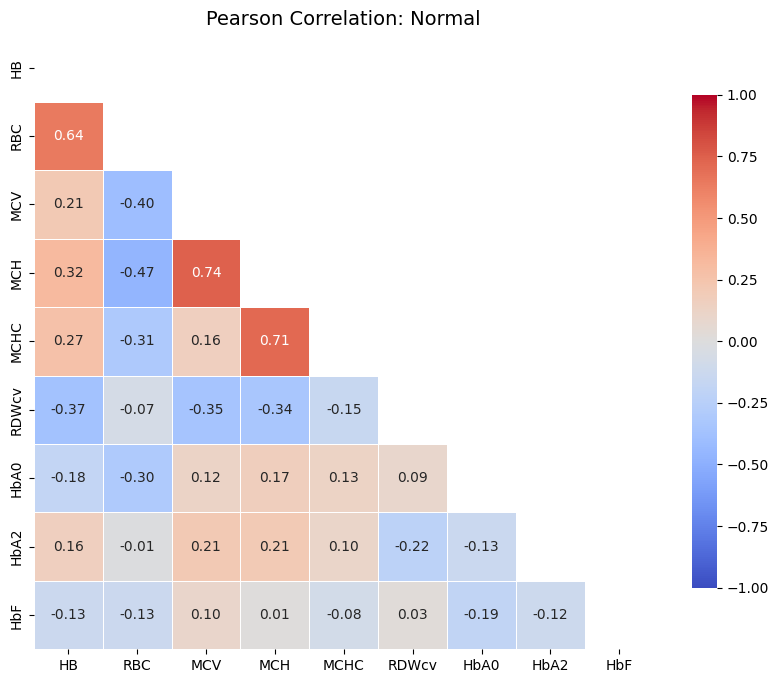

--------------------------------------------------

--- Correlation Matrix: Beta Thalassaemia carrier (N=562) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.727  0.151  0.248  0.001 -0.232 -0.096  0.070 -0.161
RBC    0.727  1.000 -0.327 -0.404 -0.049 -0.100 -0.179  0.095 -0.161
MCV    0.151 -0.327  1.000  0.722 -0.025 -0.301  0.124 -0.035  0.010
MCH    0.248 -0.404  0.722  1.000  0.086 -0.172  0.094 -0.051  0.023
MCHC   0.001 -0.049 -0.025  0.086  1.000 -0.015  0.047 -0.044 -0.018
RDWcv -0.232 -0.100 -0.301 -0.172 -0.015  1.000 -0.005  0.060  0.075
HbA0  -0.096 -0.179  0.124  0.094  0.047 -0.005  1.000 -0.305 -0.536
HbA2   0.070  0.095 -0.035 -0.051 -0.044  0.060 -0.305  1.000  0.022
HbF   -0.161 -0.161  0.010  0.023 -0.018  0.075 -0.536  0.022  1.000




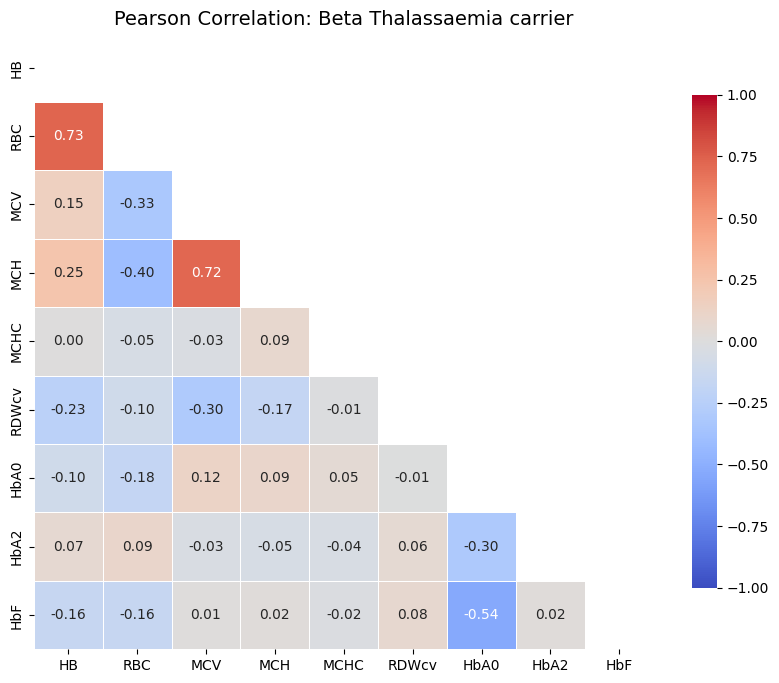

--------------------------------------------------

--- Correlation Matrix: HbE carrier (N=546) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.729  0.120  0.193  0.150 -0.207 -0.206  0.170 -0.077
RBC    0.729  1.000 -0.262 -0.405 -0.275 -0.073 -0.088  0.063 -0.107
MCV    0.120 -0.262  1.000  0.674 -0.026 -0.324 -0.059  0.091  0.112
MCH    0.193 -0.405  0.674  1.000  0.642 -0.207 -0.175  0.121  0.056
MCHC   0.150 -0.275 -0.026  0.642  1.000  0.046 -0.187  0.057 -0.028
RDWcv -0.207 -0.073 -0.324 -0.207  0.046  1.000  0.225 -0.145  0.035
HbA0  -0.206 -0.088 -0.059 -0.175 -0.187  0.225  1.000 -0.664 -0.178
HbA2   0.170  0.063  0.091  0.121  0.057 -0.145 -0.664  1.000  0.067
HbF   -0.077 -0.107  0.112  0.056 -0.028  0.035 -0.178  0.067  1.000




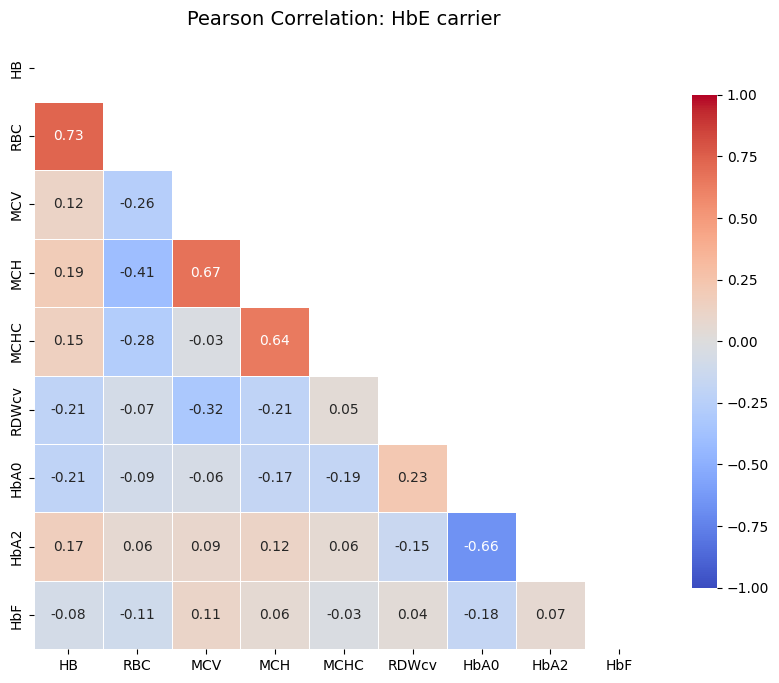

--------------------------------------------------

--- Correlation Matrix: HbE-Beta Thalassaemia (N=19) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.720  0.200  0.340  0.419 -0.450  0.176 -0.161 -0.080
RBC    0.720  1.000 -0.440 -0.381 -0.139 -0.313 -0.369  0.450  0.147
MCV    0.200 -0.440  1.000  0.918  0.386 -0.164  0.622 -0.757 -0.179
MCH    0.340 -0.381  0.918  1.000  0.716 -0.151  0.770 -0.867 -0.321
MCHC   0.419 -0.139  0.386  0.716  1.000  0.001  0.672 -0.691 -0.390
RDWcv -0.450 -0.313 -0.164 -0.151  0.001  1.000  0.013 -0.051 -0.041
HbA0   0.176 -0.369  0.622  0.770  0.672  0.013  1.000 -0.885 -0.768
HbA2  -0.161  0.450 -0.757 -0.867 -0.691 -0.051 -0.885  1.000  0.394
HbF   -0.080  0.147 -0.179 -0.321 -0.390 -0.041 -0.768  0.394  1.000




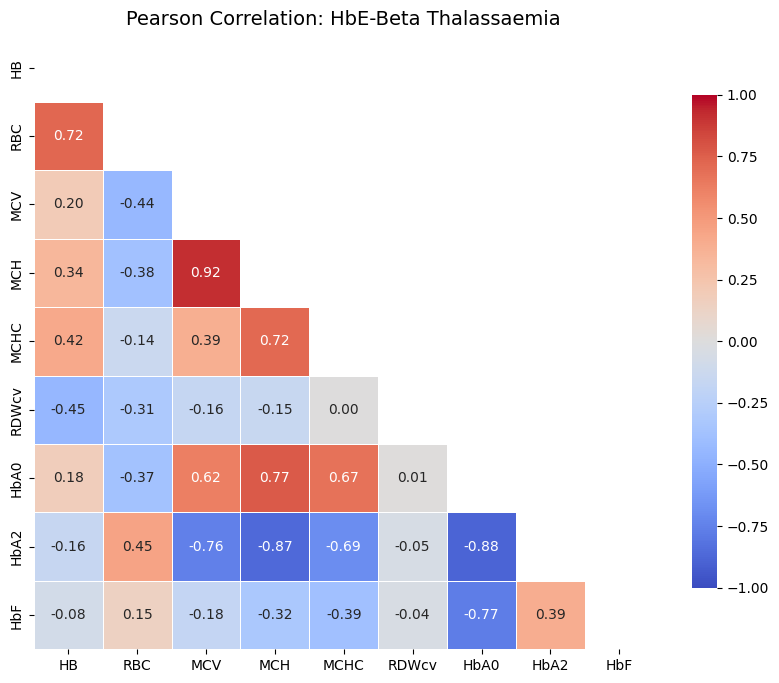

--------------------------------------------------

--- Correlation Matrix: HbS carrier (N=51) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.510  0.150  0.290  0.174 -0.391 -0.340 -0.059 -0.124
RBC    0.510  1.000 -0.563 -0.665 -0.321 -0.067  0.365  0.157 -0.262
MCV    0.150 -0.563  1.000  0.756 -0.139 -0.357 -0.534 -0.147  0.120
MCH    0.290 -0.665  0.756  1.000  0.515 -0.264 -0.691 -0.220  0.162
MCHC   0.174 -0.321 -0.139  0.515  1.000  0.102 -0.342 -0.149  0.134
RDWcv -0.391 -0.067 -0.357 -0.264  0.102  1.000  0.240  0.004 -0.082
HbA0  -0.340  0.365 -0.534 -0.691 -0.342  0.240  1.000  0.340 -0.018
HbA2  -0.059  0.157 -0.147 -0.220 -0.149  0.004  0.340  1.000 -0.173
HbF   -0.124 -0.262  0.120  0.162  0.134 -0.082 -0.018 -0.173  1.000




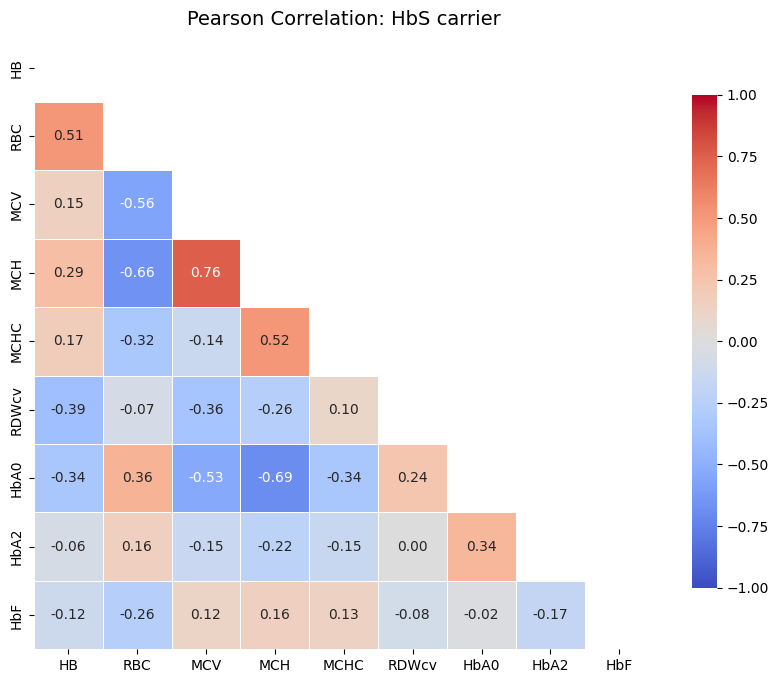

--------------------------------------------------

--- Correlation Matrix: HbD carrier (N=25) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.699  0.412  0.281  0.015 -0.457 -0.315  0.082 -0.301
RBC    0.699  1.000 -0.137 -0.469 -0.465 -0.206 -0.061 -0.045 -0.470
MCV    0.412 -0.137  1.000  0.662 -0.078 -0.319 -0.514 -0.011  0.051
MCH    0.281 -0.469  0.662  1.000  0.692 -0.298 -0.264  0.142  0.315
MCHC   0.015 -0.465 -0.078  0.692  1.000 -0.130  0.153  0.205  0.331
RDWcv -0.457 -0.206 -0.319 -0.298 -0.130  1.000  0.418 -0.025  0.429
HbA0  -0.315 -0.061 -0.514 -0.264  0.153  0.418  1.000  0.219  0.354
HbA2   0.082 -0.045 -0.011  0.142  0.205 -0.025  0.219  1.000  0.091
HbF   -0.301 -0.470  0.051  0.315  0.331  0.429  0.354  0.091  1.000




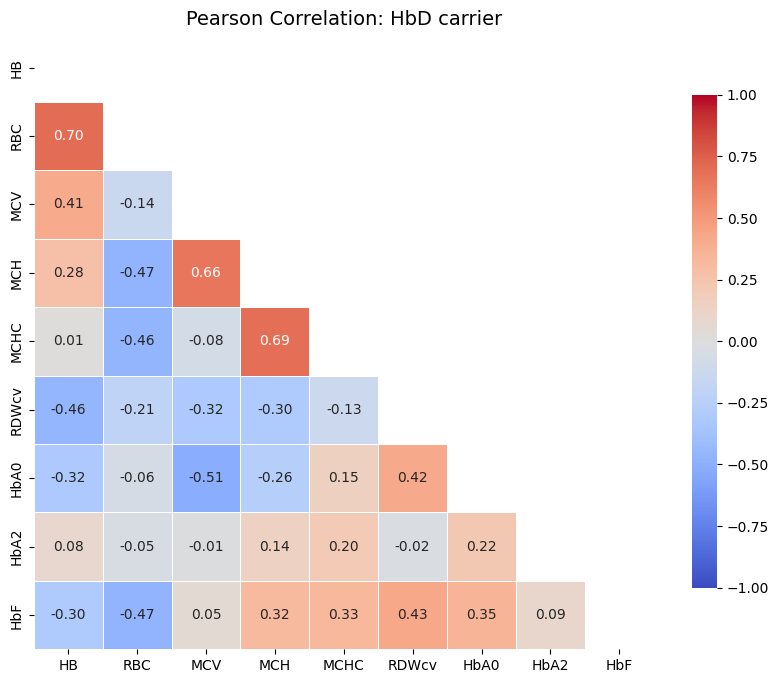

--------------------------------------------------

--- Phenotype: HbD disease ---
Skipping: Only 1 samples available. Correlation is statistically invalid.

--- Correlation Matrix: Beta Thalassaemia major (N=13) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.938  0.472  0.689  0.690 -0.786  0.714 -0.489 -0.911
RBC    0.938  1.000  0.204  0.400  0.485 -0.599  0.539 -0.394 -0.819
MCV    0.472  0.204  1.000  0.833  0.371 -0.684  0.654 -0.621 -0.510
MCH    0.689  0.400  0.833  1.000  0.823 -0.837  0.781 -0.433 -0.748
MCHC   0.690  0.485  0.371  0.823  1.000 -0.719  0.656 -0.091 -0.752
RDWcv -0.786 -0.599 -0.684 -0.837 -0.719  1.000 -0.942  0.383  0.840
HbA0   0.714  0.539  0.654  0.781  0.656 -0.942  1.000 -0.298 -0.743
HbA2  -0.489 -0.394 -0.621 -0.433 -0.091  0.383 -0.298  1.000  0.306
HbF   -0.911 -0.819 -0.510 -0.748 -0.752  0.840 -0.743  0.306  1.000




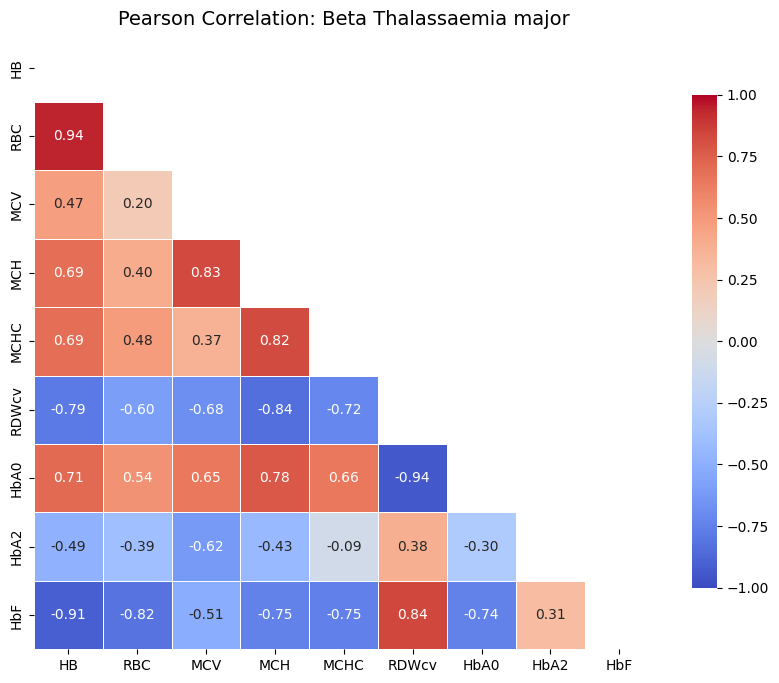

--------------------------------------------------

--- Phenotype: HPFH trait ---
Skipping: Only 2 samples available. Correlation is statistically invalid.

--- Phenotype: HbS-Beta Thalassaemia ---
Skipping: Only 2 samples available. Correlation is statistically invalid.

--- Correlation Matrix: HbE disease (N=20) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.856 -0.231 -0.231 -0.144 -0.714 -0.027  0.368 -0.718
RBC    0.856  1.000 -0.625 -0.697 -0.522 -0.457  0.094  0.231 -0.378
MCV   -0.231 -0.625  1.000  0.847  0.363 -0.148 -0.325  0.123 -0.184
MCH   -0.231 -0.697  0.847  1.000  0.801 -0.122 -0.223  0.032 -0.245
MCHC  -0.144 -0.522  0.363  0.801  1.000 -0.060 -0.017 -0.064 -0.244
RDWcv -0.714 -0.457 -0.148 -0.122 -0.060  1.000  0.477 -0.639  0.827
HbA0  -0.027  0.094 -0.325 -0.223 -0.017  0.477  1.000 -0.699  0.308
HbA2   0.368  0.231  0.123  0.032 -0.064 -0.639 -0.699  1.000 -0.646
HbF   -0.718 -0.378 -0.184 -0.245 -0.244  0.827  0.308 -0.6

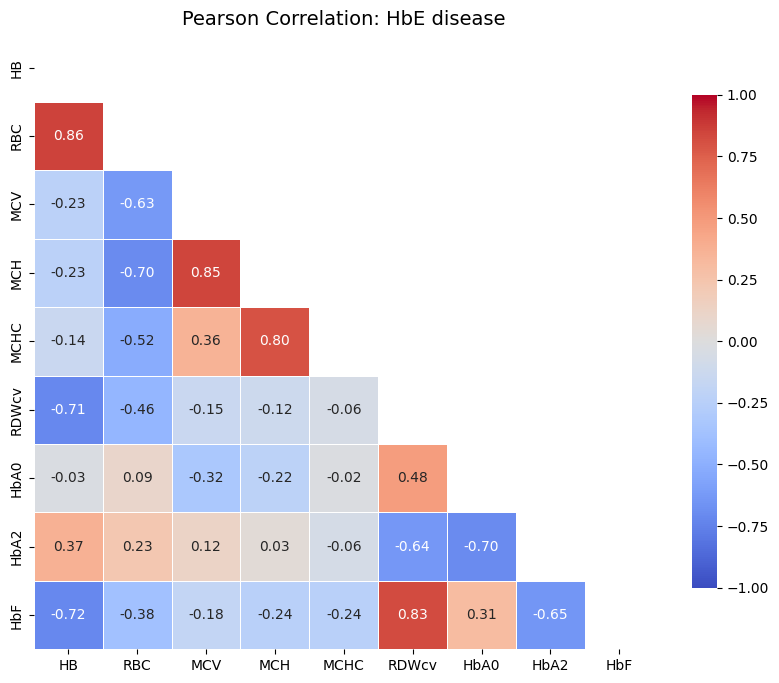

--------------------------------------------------

--- Correlation Matrix: Beta trait with high foetal haemoglobin (N=6) ---
          HB    RBC    MCV    MCH   MCHC  RDWcv   HbA0   HbA2    HbF
HB     1.000  0.817 -0.043 -0.149 -0.170 -0.566  0.711  0.342 -0.754
RBC    0.817  1.000 -0.538 -0.686 -0.320 -0.050  0.468  0.342 -0.732
MCV   -0.043 -0.538  1.000  0.829 -0.168 -0.442 -0.047  0.000  0.374
MCH   -0.149 -0.686  0.829  1.000  0.409 -0.624  0.087 -0.183  0.277
MCHC  -0.170 -0.320 -0.168  0.409  1.000 -0.421  0.267 -0.324 -0.129
RDWcv -0.566 -0.050 -0.442 -0.624 -0.421  1.000 -0.580  0.146  0.273
HbA0   0.711  0.468 -0.047  0.087  0.267 -0.580  1.000  0.615 -0.880
HbA2   0.342  0.342  0.000 -0.183 -0.324  0.146  0.615  1.000 -0.662
HbF   -0.754 -0.732  0.374  0.277 -0.129  0.273 -0.880 -0.662  1.000




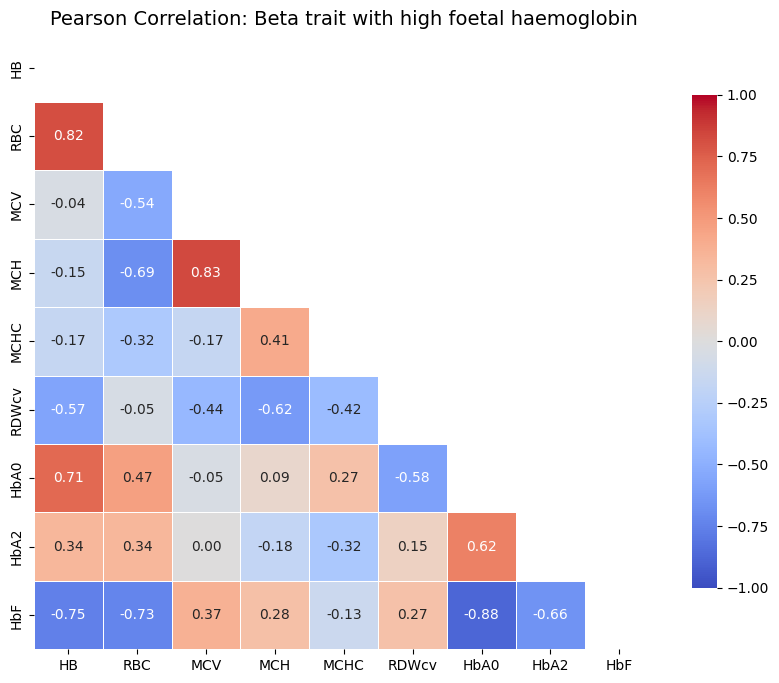

--------------------------------------------------

--- Phenotype: Delta beta carrier ---
Skipping: Only 1 samples available. Correlation is statistically invalid.



In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def generate_full_correlation_report(df_name, df_original):
    print(f"========== FULL CORRELATION REPORT: {df_name} ==========\n")
    df = df_original.copy()

    # Define the CBC and Electrophoresis parameters to correlate
    # Adjust names if your columns use different casing (e.g., 'HB' vs 'hb')
    cbc_params = ['HB', 'RBC', 'MCV', 'MCH', 'MCHC', 'RDWcv', 'HbA0', 'HbA2', 'HbF']

    # Filter for available parameters in this specific dataframe
    available_params = [p for p in cbc_params if p in df.columns]

    # Get all unique phenotypes/diagnoses
    phenotypes = df['Diagnosis'].unique()

    for pheno in phenotypes:
        # Filter data for the phenotype
        subset = df[df['Diagnosis'] == pheno][available_params]

        # We need at least 3 samples to calculate meaningful correlation
        if len(subset) < 3:
            print(f"--- Phenotype: {pheno} ---")
            print(f"Skipping: Only {len(subset)} samples available. Correlation is statistically invalid.\n")
            continue

        # Convert to numeric to avoid errors during correlation
        subset = subset.apply(pd.to_numeric, errors='coerce').dropna()

        # Calculate Pearson Correlation
        corr_matrix = subset.corr(method='pearson')

        # 1. TEXT OUTPUT: Print the raw matrix
        print(f"--- Correlation Matrix: {pheno} (N={len(subset)}) ---")
        print(corr_matrix.round(3).to_string())
        print("\n")

        # 2. VISUAL OUTPUT: Generate Heatmap
        plt.figure(figsize=(10, 8))

        # Mask the upper triangle (redundant data)
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

        sns.heatmap(corr_matrix,
                    mask=mask,
                    annot=True,
                    fmt=".2f",
                    cmap='coolwarm',
                    center=0,
                    vmin=-1, vmax=1,
                    linewidths=.5,
                    cbar_kws={"shrink": .8})

        plt.title(f"Pearson Correlation: {pheno}", fontsize=14)
        plt.show()
        print("-" * 50 + "\n")

# --- Execute for West Bengal / Bangladesh Dataframes ---
# Replace with the actual keys in your 'dataframes' dictionary
if 'westbengal_df' in dataframes:
    generate_full_correlation_report('West Bengal', dataframes['westbengal_df'])

========== FULL CORRELATION REPORT: West Bengal ==========



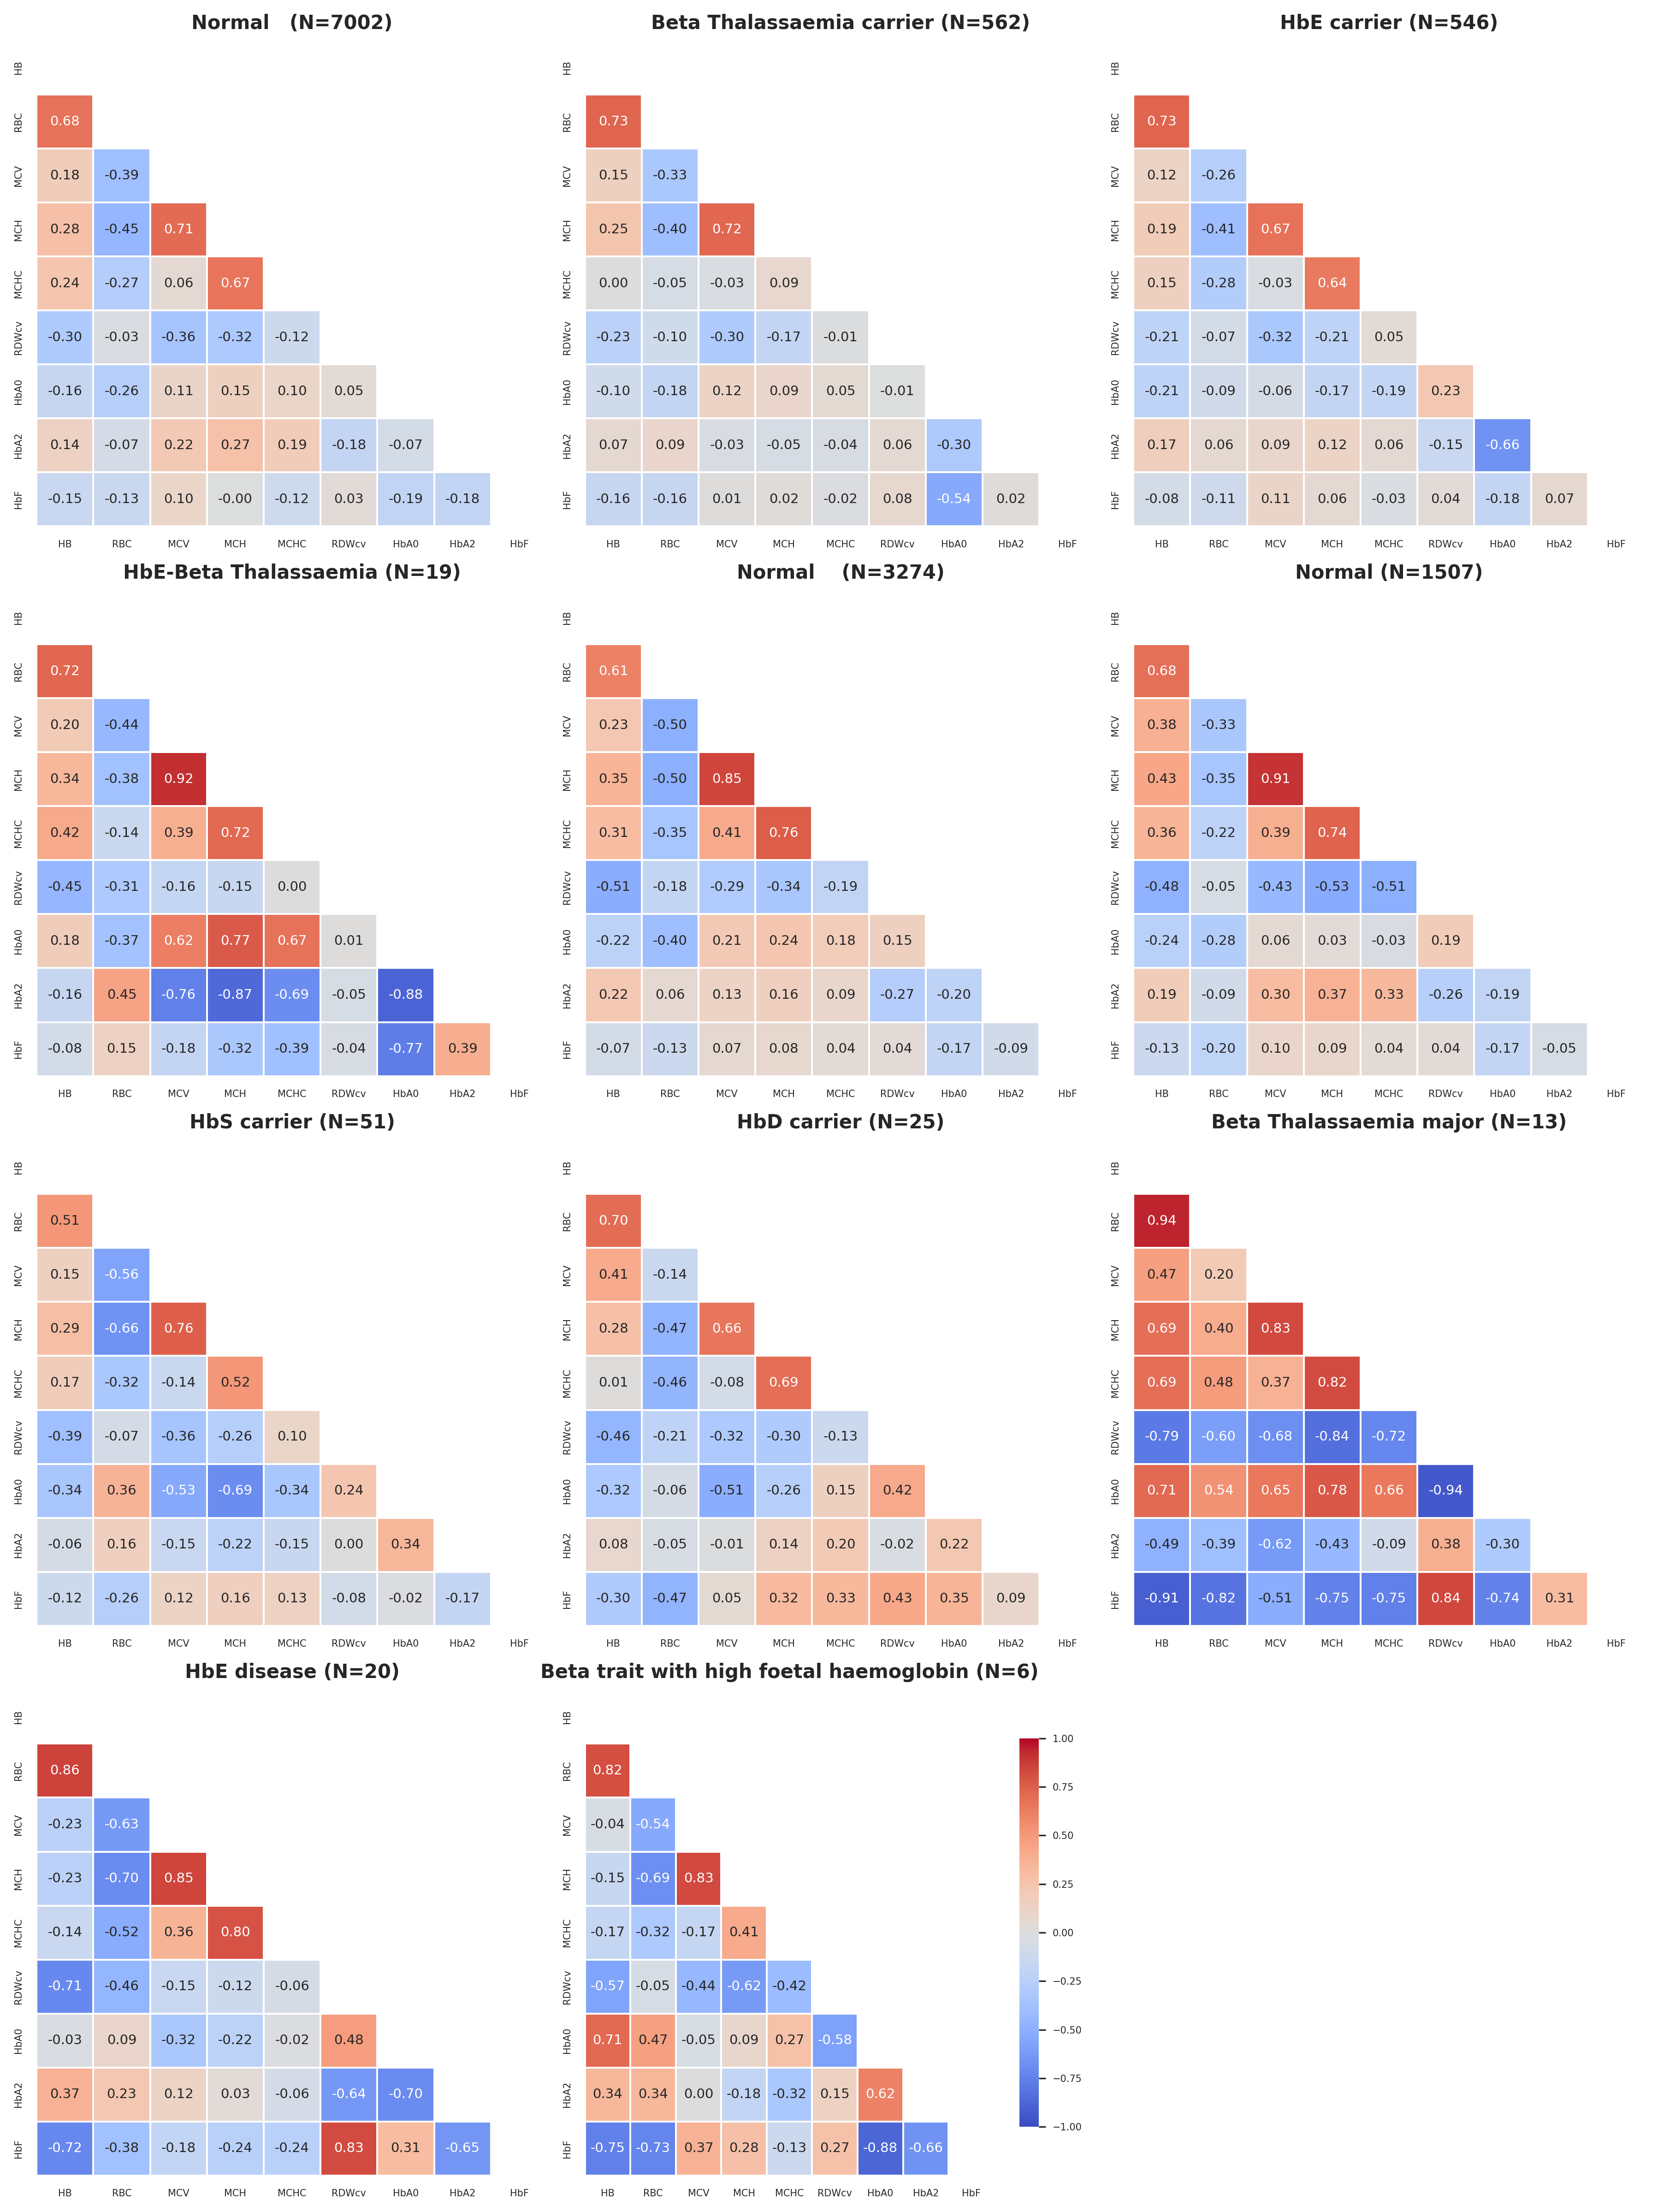

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math

def generate_full_correlation_report(df_name, df_original):

    print(f"========== FULL CORRELATION REPORT: {df_name} ==========\n")

    df = df_original.copy()

    cbc_params = [
        'HB',
        'RBC',
        'MCV',
        'MCH',
        'MCHC',
        'RDWcv',
        'HbA0',
        'HbA2',
        'HbF'
    ]

    available_params = [
        p for p in cbc_params
        if p in df.columns
    ]

    phenotypes = df['Diagnosis'].dropna().unique()

    valid_phenotypes = []

    for pheno in phenotypes:

        subset = df[
            df['Diagnosis'] == pheno
        ][available_params]

        subset = subset.apply(
            pd.to_numeric,
            errors='coerce'
        ).dropna()

        if len(subset) >= 3:
            valid_phenotypes.append(pheno)

    n_panels = len(valid_phenotypes)
    ncols = 3
    nrows = math.ceil(n_panels / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4*ncols, 4*nrows)
    )

    axes = np.array(axes).flatten()

    for i, pheno in enumerate(valid_phenotypes):

        subset = df[
            df['Diagnosis'] == pheno
        ][available_params]

        subset = subset.apply(
            pd.to_numeric,
            errors='coerce'
        ).dropna()

        corr_matrix = subset.corr(
            method='pearson'
        )

        ax = axes[i]

        mask = np.triu(
            np.ones_like(
                corr_matrix,
                dtype=bool
            )
        )

        sns.heatmap(
            corr_matrix,
            mask=mask,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            center=0,
            vmin=-1,
            vmax=1,
            linewidths=.5,
            cbar=(i == len(valid_phenotypes)-1),
            cbar_kws={"shrink": .8},
            ax=ax
        )

        ax.set_title(
            f"{pheno} (N={len(subset)})",
            fontsize=10,
            fontweight='bold'
        )

    for j in range(
        len(valid_phenotypes),
        len(axes)
    ):
        fig.delaxes(axes[j])

    plt.tight_layout()

    plt.savefig(
        "WestBengal_All_Correlations.png",
        dpi=1200,
        bbox_inches="tight"
    )

    plt.savefig(
        "WestBengal_All_Correlations.pdf",
        dpi=1200,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# RUN
# ============================================================

if 'westbengal_df' in dataframes:
    generate_full_correlation_report(
        'West Bengal',
        dataframes['westbengal_df']
    )

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import warnings

warnings.filterwarnings('ignore')

def train_and_evaluate_models(df_name, df_original):
    print(f"--- Processing {df_name} ---")
    df = df_original.copy()
    relevant_columns = [
        'hb', 'pcv', 'rbc', 'mcv', 'mch', 'mchc', 'rdw', 'wbc', 'neut', 'lymph', 'plt',
        'hba', 'hba2', 'hbf', 'sex', 'phenotype'
    ]

    existing_relevant_columns = [col for col in relevant_columns if col in df.columns]

    if len(existing_relevant_columns) < 2: # Need at least one feature and the target
        print(f"Not enough relevant columns found in {df_name}. Skipping model training.")
        return []

    df = df.dropna(subset=existing_relevant_columns)

    if df.empty:
        print(f"DataFrame {df_name} is empty after dropping NaNs. Skipping model training.")
        return []

    le_sex = LabelEncoder()
    df['sex_encoded'] = le_sex.fit_transform(df['sex'])
    print(f"Sex encoding for {df_name}: {list(le_sex.classes_)} -> {le_sex.transform(le_sex.classes_)}")

    # Encode 'phenotype' column (target variable)
    le_phenotype = LabelEncoder()
    df['phenotype_encoded'] = le_phenotype.fit_transform(df['phenotype'])
    print(f"Phenotype encoding for {df_name}: {list(le_phenotype.classes_)} -> {le_phenotype.transform(le_phenotype.classes_)}")
    feature_columns = [col for col in existing_relevant_columns if col not in ['sex', 'phenotype']]
    feature_columns.append('sex_encoded') # Add the encoded sex column
    X = df[feature_columns]
    y = df['phenotype_encoded']
    if len(y.unique()) < 2:
        print(f"Only one phenotype class found in {df_name} after preprocessing. Cannot perform classification.")
        return []
    if len(X) < 2:
        print(f"Not enough samples in {df_name} after preprocessing. Skipping model training.")
        return []

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    models = {
        "Logistic Regression": LogisticRegression(random_state=42, solver='liblinear'),
        "RandomForest Classifier": RandomForestClassifier(random_state=42),
        "XGBoost Classifier": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    }

    results = []

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

        roc_auc = 'N/A'
        # Check if the model has predict_proba for AUC calculation
        if hasattr(model, 'predict_proba') and len(y.unique()) == 2: # AUC is typically for binary classification
            y_pred_proba = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(y_test, y_pred_proba, average='weighted')

        results.append({
            "DataFrame": df_name,
            "Model": model_name,
            "Accuracy": f"{accuracy:.4f}",
            "Precision": f"{precision:.4f}",
            "Recall": f"{recall:.4f}",
            "F1-Score": f"{f1:.4f}",
            "AUC": f"{roc_auc:.4f}" if roc_auc != 'N/A' else 'N/A'
        })
        print(f"{model_name} Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1:.4f}, AUC: {roc_auc:.4f}")
    print("-" * 30)
    return results

all_results = []

# Process alphanorm_df
alphanorm_df = dataframes['alphanorm_df']
all_results.extend(train_and_evaluate_models('alphanorm_df', alphanorm_df))

# Process twoalphas_df
twoalphas_df = dataframes['twoalphas_df']
all_results.extend(train_and_evaluate_models('twoalphas_df', twoalphas_df))

# Create and display the comparison table
comparison_table = pd.DataFrame(all_results)
print("\n--- Model Comparison Table ---")
display(comparison_table)

--- Processing alphanorm_df ---
Sex encoding for alphanorm_df: ['female', 'male'] -> [0 1]
Phenotype encoding for alphanorm_df: ['alpha carrier', 'normal'] -> [0 1]
Logistic Regression Accuracy: 0.7000, Precision: 0.6036, Recall: 0.7000, F1-Score: 0.6280, AUC: 0.4872
RandomForest Classifier Accuracy: 0.6833, Precision: 0.5275, Recall: 0.6833, F1-Score: 0.5954, AUC: 0.6676
XGBoost Classifier Accuracy: 0.7000, Precision: 0.6321, Recall: 0.7000, F1-Score: 0.6471, AUC: 0.6591
------------------------------
--- Processing twoalphas_df ---
Sex encoding for twoalphas_df: ['female', 'male'] -> [0 1]
Phenotype encoding for twoalphas_df: ['alpha trait', 'silent carrier'] -> [0 1]
Logistic Regression Accuracy: 0.7500, Precision: 0.7259, Recall: 0.7500, F1-Score: 0.7262, AUC: 0.8203
RandomForest Classifier Accuracy: 0.7500, Precision: 0.7724, Recall: 0.7500, F1-Score: 0.7577, AUC: 0.8411
XGBoost Classifier Accuracy: 0.7045, Precision: 0.7292, Recall: 0.7045, F1-Score: 0.7137, AUC: 0.8255
---------

,DataFrame,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,alphanorm_df,Logistic Regression,0.7000,0.6036,0.7000,0.6280,0.4872
1,alphanorm_df,RandomForest Classifier,0.6833,0.5275,0.6833,0.5954,0.6676
2,alphanorm_df,XGBoost Classifier,0.7000,0.6321,0.7000,0.6471,0.6591
3,twoalphas_df,Logistic Regression,0.7500,0.7259,0.7500,0.7262,0.8203
4,twoalphas_df,RandomForest Classifier,0.7500,0.7724,0.7500,0.7577,0.8411
5,twoalphas_df,XGBoost Classifier,0.7045,0.7292,0.7045,0.7137,0.8255


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def run_comprehensive_evaluation(df_name, df_original):

    df = df_original.copy()

    print(f"\n{'='*25} Evaluating: {df_name} {'='*25}")

    df.columns = df.columns.str.lower().str.strip()

    le = LabelEncoder()
    df['target_encoded'] = le.fit_transform(df['phenotype'].astype(str))

    y_true = df['target_encoded']

    hb = pd.to_numeric(df['hb'], errors='coerce')
    rbc = pd.to_numeric(df['rbc'], errors='coerce')
    mcv = pd.to_numeric(df['mcv'], errors='coerce')
    mch = pd.to_numeric(df['mch'], errors='coerce')
    rdw = pd.to_numeric(df['rdw'], errors='coerce')

    indices = {
        "Mentzer": (mcv / rbc),
        "England & Fraser": (mcv - (5 * hb) - rbc - 3.4),
        "Shine-Lal": ((mcv ** 2) * mch) / 100,
        "Srivastava": (mch / rbc),
        "Green & King": ((mcv ** 2) * rdw) / (hb * 100),
        "Ricerca": (rdw / rbc),
        "Ehsani": (mcv - (10 * rbc)),
        "Sirdah": (mcv - rbc - (3 * hb)),
        "RDWI": ((mcv * rdw) / rbc),
        "Bessman": rdw
    }

    thresholds = {
        "Mentzer": 13,
        "England & Fraser": 0,
        "Shine-Lal": 1530,
        "Srivastava": 3.8,
        "Green & King": 65,
        "Ricerca": 4.4,
        "Ehsani": 15,
        "Sirdah": 27,
        "RDWI": 220,
        "Bessman": 15
    }

    lower_is_positive = {
        "Mentzer": True,
        "England & Fraser": True,
        "Shine-Lal": True,
        "Srivastava": True,
        "Green & King": False,
        "Ricerca": False,
        "Ehsani": True,
        "Sirdah": True,
        "RDWI": True,
        "Bessman": False
    }

    results = []

    for method, score in indices.items():

        valid_mask = ~(score.isna())

        y_true_valid = y_true[valid_mask]
        score_valid = score[valid_mask]

        if lower_is_positive[method]:
            y_pred = (score_valid < thresholds[method]).astype(int)
            auc_score = roc_auc_score(y_true_valid, -score_valid)
        else:
            y_pred = (score_valid > thresholds[method]).astype(int)
            auc_score = roc_auc_score(y_true_valid, score_valid)

        results.append({
            "Dataset": df_name,
            "Method": method,
            "Accuracy": round(
                accuracy_score(y_true_valid, y_pred), 4
            ),
            "F1-Score": round(
                f1_score(
                    y_true_valid,
                    y_pred,
                    average='weighted',
                    zero_division=0
                ), 4
            ),
            "AUC": round(auc_score, 4)
        })

    comparison_df = (
        pd.DataFrame(results)
        .sort_values(by='AUC', ascending=False)
        .reset_index(drop=True)
    )

    display(comparison_df)

    return comparison_df


selected_datasets = {
    "alphanorm_df": dataframes["alphanorm_df"],
    "twoalphas_df": dataframes["twoalphas_df"]
}

all_results = []

for df_name, df_data in selected_datasets.items():

    result = run_comprehensive_evaluation(df_name, df_data)

    if result is not None:
        all_results.append(result)

final_results = pd.concat(all_results, ignore_index=True)

print("\nCombined Evaluation Across Selected Cohorts")

display(final_results)


========================= Evaluating: alphanorm_df =========================


,Dataset,Method,Accuracy,F1-Score,AUC
0,alphanorm_df,Sirdah,0.6535,0.6445,0.5952
1,alphanorm_df,Ehsani,0.6485,0.6454,0.5873
2,alphanorm_df,Mentzer,0.6287,0.6317,0.5852
3,alphanorm_df,England & Fraser,0.6287,0.6298,0.5837
4,alphanorm_df,Shine-Lal,0.5075,0.5311,0.5808
5,alphanorm_df,Srivastava,0.6750,0.6440,0.5741
6,alphanorm_df,Bessman,0.5911,0.6060,0.5549
7,alphanorm_df,RDWI,0.4950,0.5186,0.5488
8,alphanorm_df,Ricerca,0.7079,0.6115,0.5012
9,alphanorm_df,Green & King,0.4631,0.4927,0.4512



========================= Evaluating: twoalphas_df =========================


,Dataset,Method,Accuracy,F1-Score,AUC
0,twoalphas_df,Green & King,0.5034,0.5262,0.5310
1,twoalphas_df,RDWI,0.5306,0.5448,0.4353
2,twoalphas_df,England & Fraser,0.3673,0.3709,0.4255
3,twoalphas_df,Ricerca,0.2721,0.1444,0.4016
4,twoalphas_df,Sirdah,0.3401,0.3473,0.3308
5,twoalphas_df,Srivastava,0.2945,0.2671,0.3074
6,twoalphas_df,Bessman,0.3673,0.3964,0.2983
7,twoalphas_df,Mentzer,0.3129,0.3349,0.2938
8,twoalphas_df,Ehsani,0.2925,0.3085,0.2781
9,twoalphas_df,Shine-Lal,0.5205,0.5127,0.2563



Combined Evaluation Across Selected Cohorts


,Dataset,Method,Accuracy,F1-Score,AUC
0,alphanorm_df,Sirdah,0.6535,0.6445,0.5952
1,alphanorm_df,Ehsani,0.6485,0.6454,0.5873
2,alphanorm_df,Mentzer,0.6287,0.6317,0.5852
3,alphanorm_df,England & Fraser,0.6287,0.6298,0.5837
4,alphanorm_df,Shine-Lal,0.5075,0.5311,0.5808
5,alphanorm_df,Srivastava,0.6750,0.6440,0.5741
6,alphanorm_df,Bessman,0.5911,0.6060,0.5549
7,alphanorm_df,RDWI,0.4950,0.5186,0.5488
8,alphanorm_df,Ricerca,0.7079,0.6115,0.5012
9,alphanorm_df,Green & King,0.4631,0.4927,0.4512



Processing alphanorm_df...


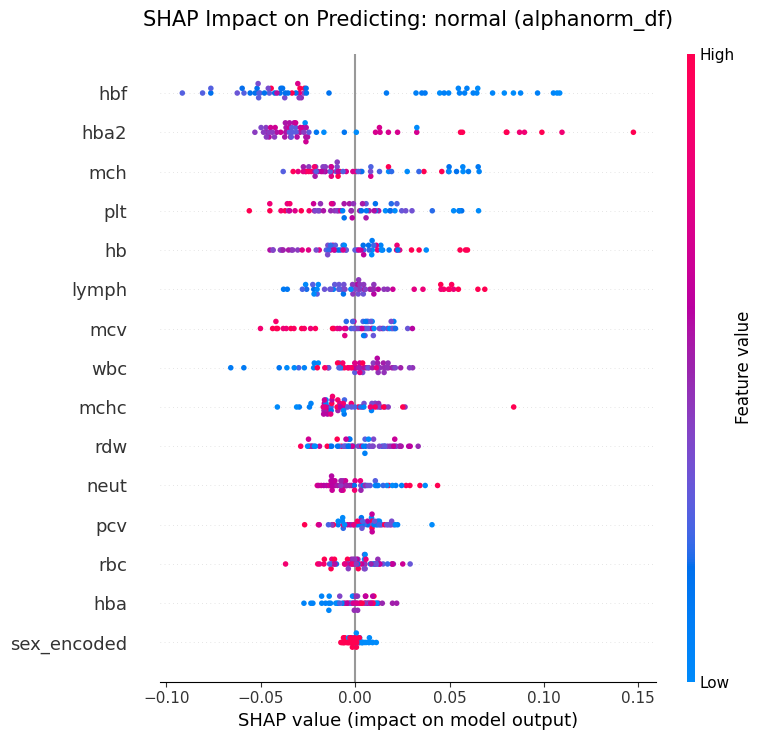


Processing twoalphas_df...


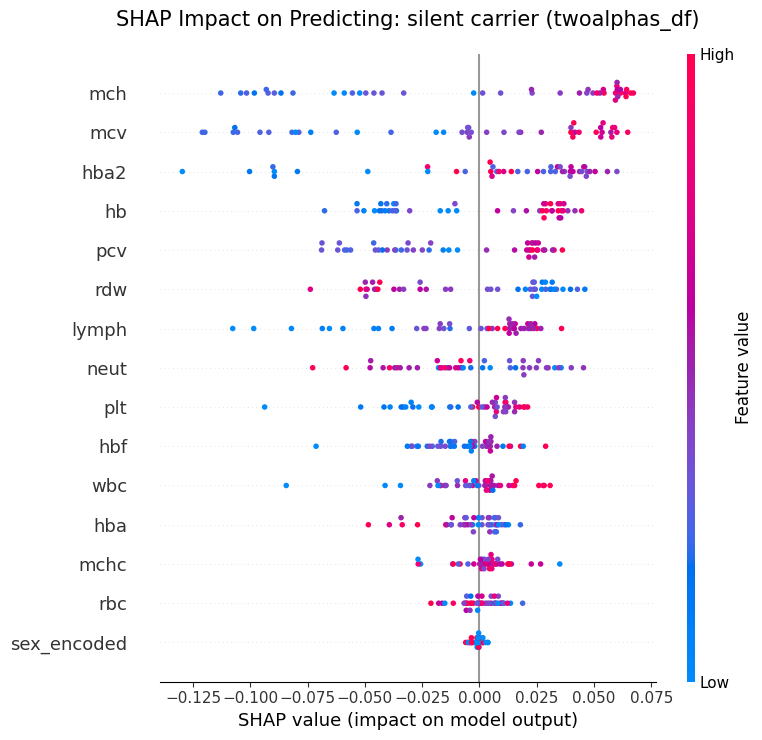

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import shap
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

def get_model_and_data_for_shap(df_name, df_original):
    df = df_original.copy()

    # List all possible terms found across these specific dataframes
    # We will dynamically keep only what exists in the current df
    potential_features = [
        'hb', 'pcv', 'rbc', 'mcv', 'mch', 'mchc', 'rdw', 'wbc',
        'neut', 'lymph', 'plt', 'hba', 'hba2', 'hbf'
    ]

    existing_features = [col for col in potential_features if col in df.columns]

    # Drop rows missing features or the labels
    required_cols = existing_features + ['sex', 'phenotype']
    df = df.dropna(subset=required_cols)

    if df.empty or len(df) < 10:
        print(f"Skipping {df_name}: Too few samples ({len(df)}).")
        return None, None, None, None, None

    # Encoding
    le_sex = LabelEncoder()
    df['sex_encoded'] = le_sex.fit_transform(df['sex'])
    le_phenotype = LabelEncoder()
    df['target'] = le_phenotype.fit_transform(df['phenotype'])

    final_features = existing_features + ['sex_encoded']
    X = df[final_features]
    y = df['target']

    if len(y.unique()) < 2:
        print(f"Skipping {df_name}: Only one class present.")
        return None, None, None, None, None

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)

    return rf_model, X_test, y_test, final_features, le_phenotype

def plot_shap_beeswarm(rf_model, X_test, le_phenotype, title):
    # Create the explainer
    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_test)

    # For binary classification, shap_values is a list: [values_for_class_0, values_for_class_1]
    # We want class 1 (usually the disease/trait state)
    if isinstance(shap_values, list):
        sv = shap_values[1]
    else:
        # Some versions return a 3D array (samples, features, classes)
        sv = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

    # Create a SHAP Explanation object to force the correct beeswarm behavior
    # This is the 'modern' way to ensure the plot looks right
    exp = shap.Explanation(
        values=sv,
        data=X_test.values,
        feature_names=X_test.columns.tolist(),
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value
    )

    plt.figure(figsize=(12, 8))
    # Using the explanation object directly triggers the best beeswarm render
    shap.plots.beeswarm(exp, max_display=len(X_test.columns), show=False)
    plt.title(title, fontsize=15, pad=20)
    plt.tight_layout()
    plt.show()

# --- Execution ---
for name in ['alphanorm_df', 'twoalphas_df']:
    print(f"\nProcessing {name}...")
    model, X_t, y_t, feats, le = get_model_and_data_for_shap(name, dataframes[name])

    if model is not None:
        target_name = le.classes_[1]
        plot_shap_beeswarm(model, X_t, le, f"SHAP Impact on Predicting: {target_name} ({name})")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import warnings

warnings.filterwarnings('ignore')

def train_and_evaluate_models_ida(df_name, df_original):
    print(f"--- Processing {df_name} ---")
    df = df_original.copy()
    df = df.drop(columns=['ID', 'pname'], errors='ignore')
    target_column = 'Class'
    feature_columns = [col for col in df.columns if col != target_column]

    if target_column not in df.columns:
        print(f"Target column '{target_column}' not found in {df_name}. Skipping model training.")
        return []
    if df[target_column].nunique() < 2:
        print(f"Only one class found in '{target_column}' for {df_name}. Cannot perform classification.")
        return []
    df = df.dropna(subset=feature_columns + [target_column])

    if df.empty:
        print(f"DataFrame {df_name} is empty after dropping NaNs. Skipping model training.")
        return []
    if len(df) < 2: # Need at least 2 samples for train/test split
        print(f"Not enough samples in {df_name} after dropping NaNs. Skipping model training.")
        return []

    X = df[feature_columns]
    y = df[target_column]
    if X.empty or len(y.unique()) < 2 or len(y) < 2:
        print(f"Insufficient data or classes for stratification in {df_name}. Skipping model training.")
        return []
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    models = {
        "Logistic Regression": LogisticRegression(random_state=42, solver='liblinear'),
        "RandomForest Classifier": RandomForestClassifier(random_state=42),
        "XGBoost Classifier": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    }

    results = []

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

        roc_auc = 'N/A'
        if hasattr(model, 'predict_proba') and len(y.unique()) == 2:
            y_pred_proba = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(y_test, y_pred_proba, average='weighted')

        results.append({
            "DataFrame": df_name,
            "Model": model_name,
            "Accuracy": f"{accuracy:.4f}",
            "Precision": f"{precision:.4f}",
            "Recall": f"{recall:.4f}",
            "F1-Score": f"{f1:.4f}",
            "AUC": f"{roc_auc:.4f}" if roc_auc != 'N/A' else 'N/A'
        })
        print(f"{model_name} Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1:.4f}, AUC: {roc_auc:.4f}")
    print("-" * 30)
    return results
ida_btt_df = dataframes['IDA_BTT_df']
ida_btt_results = train_and_evaluate_models_ida('IDA_BTT_df', ida_btt_df)
comparison_table_ida = pd.DataFrame(ida_btt_results)
print("\n--- Model Comparison Table for IDA_BTT_df ---")
display(comparison_table_ida)

--- Processing IDA_BTT_df ---
Logistic Regression Accuracy: 0.9467, Precision: 0.9499, Recall: 0.9467, F1-Score: 0.9427, AUC: 0.9169
RandomForest Classifier Accuracy: 0.9733, Precision: 0.9742, Recall: 0.9733, F1-Score: 0.9724, AUC: 0.9007
XGBoost Classifier Accuracy: 0.9467, Precision: 0.9455, Recall: 0.9467, F1-Score: 0.9449, AUC: 0.9094
------------------------------

--- Model Comparison Table for IDA_BTT_df ---


,DataFrame,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,IDA_BTT_df,Logistic Regression,0.9467,0.9499,0.9467,0.9427,0.9169
1,IDA_BTT_df,RandomForest Classifier,0.9733,0.9742,0.9733,0.9724,0.9007
2,IDA_BTT_df,XGBoost Classifier,0.9467,0.9455,0.9467,0.9449,0.9094


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_clinical_indices(df_original, target_col='Class'):
    df = df_original.copy()

    # Standardizing column names for the formulas
    rename_map = {
        'CBC_MCV': 'MCV', 'CBC_RBC': 'RBC', 'Hb': 'HB',
        'CBC_MCH': 'MCH', 'CBC_RDW': 'RDW', 'CBC_MCHC': 'MCHC'
    }
    df = df.rename(columns=rename_map)
    y_true = df[target_col]

    # --- DEFINE FORMULAS ---
    indices = {
        "Mentzer": lambda d: d['MCV'] / d['RBC'],
        "England & Fraser": lambda d: d['MCV'] - (5 * d['HB']) - d['RBC'] - 3.4,
        "Shine-Lal": lambda d: (d['MCV']**2 * d['MCH']) / 100,
        "Srivastava": lambda d: d['MCH'] / d['RBC'],
        "Green & King": lambda d: (d['MCV']**2 * d['RDW']) / (d['HB'] * 100),
        "Ricerca": lambda d: d['RDW'] / d['RBC'],
        "Ehsani": lambda d: d['MCV'] - (10 * d['RBC']),
        "Sirdah": lambda d: d['MCV'] - d['RBC'] - (3 * d['HB']),
        "RDWI": lambda d: (d['MCV'] * d['RDW']) / d['RBC'],
        "Bessman": lambda d: d['RDW']
    }

    # --- DEFINE THRESHOLDS (Lower value typically suggests Thalassemia/Class 1) ---
    thresholds = {
        "Mentzer": 13, "England & Fraser": 0, "Shine-Lal": 1530,
        "Srivastava": 3.8, "Green & King": 65, "Ricerca": 4.4,
        "Ehsani": 15, "Sirdah": 27, "RDWI": 220, "Bessman": 15
    }

    results = []
    for name, formula in indices.items():
        val = formula(df)
        # Class 1 = BTT, Class 0 = IDA.
        # For most indices, < Threshold is BTT (1).
        y_pred = (val < thresholds[name]).astype(int)

        # Calculate metrics
        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)

        # AUC calculation (lower index value = higher probability of disease)
        try:
            auc = roc_auc_score(y_true, -val)
        except:
            auc = 0.5

        results.append({
            "Method": name, "Accuracy": acc, "Precision": prec,
            "Recall": rec, "F1-Score": f1, "AUC": auc
        })

    return pd.DataFrame(results).sort_values(by="AUC", ascending=False)

# Execute
indices_comparison = evaluate_clinical_indices(dataframes['IDA_BTT_df'])
print("--- TRADITIONAL INDICES PERFORMANCE ---")
display(indices_comparison)

--- TRADITIONAL INDICES PERFORMANCE ---


,Method,Accuracy,Precision,Recall,F1-Score,AUC
4,Green & King,0.944,0.969697,0.711111,0.820513,0.912087
8,RDWI,0.944,0.969697,0.711111,0.820513,0.903848
5,Ricerca,0.900,0.727273,0.711111,0.719101,0.898482
9,Bessman,0.936,0.939394,0.688889,0.794872,0.872087
1,England & Fraser,0.836,1.000000,0.088889,0.163265,0.801897
3,Srivastava,0.836,0.833333,0.111111,0.196078,0.779729
0,Mentzer,0.828,0.625000,0.111111,0.188679,0.771057
7,Sirdah,0.832,0.714286,0.111111,0.192308,0.742385
6,Ehsani,0.828,0.625000,0.111111,0.188679,0.701626
2,Shine-Lal,0.416,0.156463,0.511111,0.239583,0.427046


In [ ]:
print(dataframes['IDA_BTT_df']['Class'].value_counts())

Class
0    205
1     45
Name: count, dtype: int64



Processing IDA_BTT_df for SHAP plot...


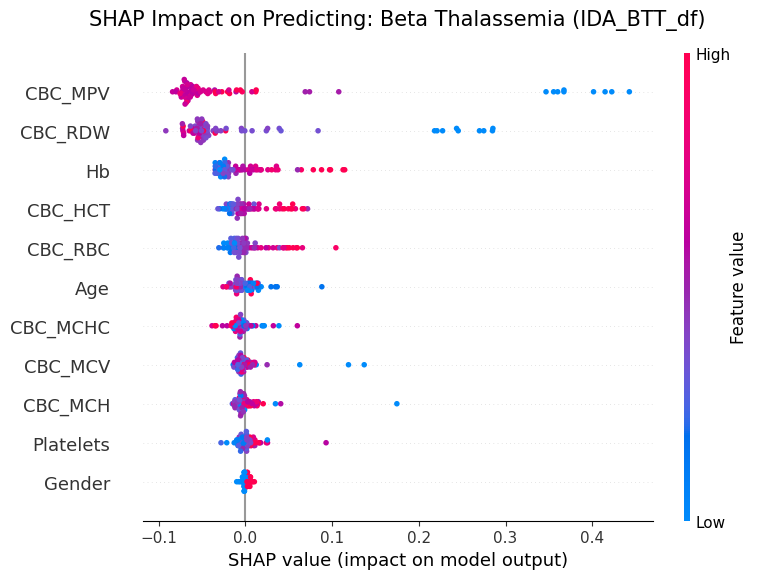

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import shap
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

def get_model_and_data_for_shap_ida(df_name, df_original):
    df = df_original.copy()

    # Drop 'ID' and 'pname' columns as requested earlier
    df = df.drop(columns=['ID', 'pname'], errors='ignore')

    # Identify target column
    target_column = 'Class'

    # Exclude target column from features
    feature_columns = [col for col in df.columns if col != target_column]

    # Drop rows with any NaN values in feature or target columns
    df = df.dropna(subset=feature_columns + [target_column])

    if df.empty or len(df) < 10:
        print(f"Skipping {df_name}: Too few samples ({len(df)}).")
        return None, None, None, None, None

    X = df[feature_columns]
    y = df[target_column]

    # Ensure target column has at least two unique classes for stratification
    if y.nunique() < 2:
        print(f"Skipping {df_name}: Only one class present for target '{target_column}'.")
        return None, None, None, None, None

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)

    # Create a dummy LabelEncoder to get class names if needed by plot_shap_beeswarm
    # Since 'Class' is 0 or 1, we can manually define these.
    le_dummy = LabelEncoder()
    le_dummy.fit([0, 1]) # Assuming classes are 0 and 1

    return rf_model, X_test, y_test, feature_columns, le_dummy

def plot_shap_beeswarm(rf_model, X_test, le_phenotype, title):
    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_test)

    # For binary classification, shap_values is a list: [values_for_class_0, values_for_class_1]
    # We want class 1 (usually the positive/disease state)
    if isinstance(shap_values, list):
        sv = shap_values[1]
    else:
        sv = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

    # Create a SHAP Explanation object
    exp = shap.Explanation(
        values=sv,
        data=X_test.values,
        feature_names=X_test.columns.tolist(),
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value
    )

    plt.figure(figsize=(12, 8))
    shap.plots.beeswarm(exp, max_display=len(X_test.columns), show=False)
    plt.title(title, fontsize=15, pad=20)
    plt.tight_layout()
    plt.show()

# --- Execution for IDA_BTT_df ---
print(f"\nProcessing IDA_BTT_df for SHAP plot...")
model_ida, X_test_ida, y_test_ida, features_ida, le_ida = get_model_and_data_for_shap_ida('IDA_BTT_df', dataframes['IDA_BTT_df'])

if model_ida is not None:
    # Assuming 'Class' 1 is the positive class
    target_name_ida = le_ida.inverse_transform([1])[0] # Get the label for class 1
    plot_shap_beeswarm(model_ida, X_test_ida, le_ida, f"SHAP Impact on Predicting: Beta Thalassemia (IDA_BTT_df)")

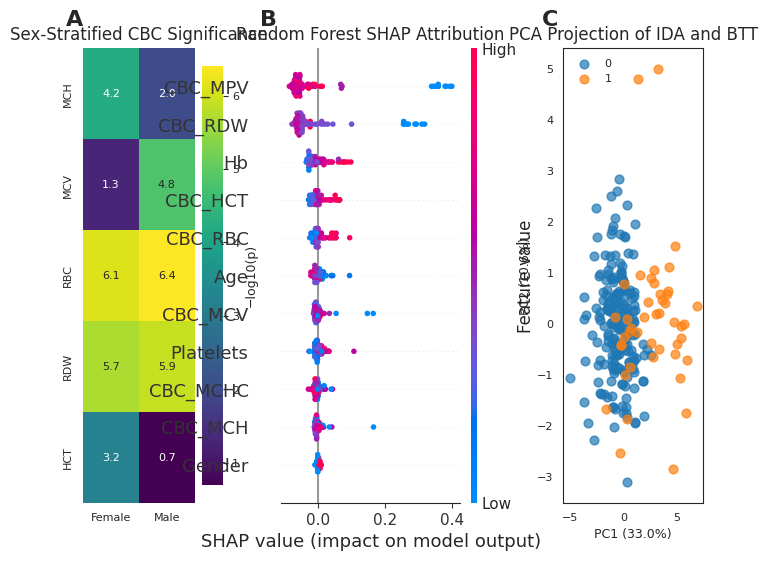

In [ ]:
import pandas as pd
import numpy as np
import shap
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ============================================================
# DATA
# ============================================================

df = dataframes['IDA_BTT_df'].copy()

df = df.drop(columns=['ID', 'pname'], errors='ignore')
df = df.dropna()

target_col = "Class"

X = df.drop(columns=[target_col])
y = df[target_col]

# ============================================================
# TRAIN RF FOR SHAP
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

# ============================================================
# SHAP
# ============================================================

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    sv = shap_values[1]
    base_val = explainer.expected_value[1]
else:
    sv = shap_values[:, :, 1]
    base_val = explainer.expected_value[1]

# ============================================================
# PCA
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:,0],
    "PC2": X_pca[:,1],
    "Class": y
})

# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(figsize=(30,7))

gs = fig.add_gridspec(
    1,
    3,
    width_ratios=[1.0, 1.6, 1.0],
    wspace=0.35
)

# ============================================================
# PANEL A
# Replace with your actual significance matrix
# ============================================================

ax1 = fig.add_subplot(gs[0])

heatmap_data = pd.DataFrame(
    {
        "Female":[
            4.2,
            1.3,
            6.1,
            5.7,
            3.2
        ],
        "Male":[
            2.0,
            4.8,
            6.4,
            5.9,
            0.7
        ]
    },
    index=[
        "MCH",
        "MCV",
        "RBC",
        "RDW",
        "HCT"
    ]
)

sns.heatmap(
    heatmap_data,
    cmap="viridis",
    annot=True,
    fmt=".1f",
    cbar_kws={"label":"−log10(p)"},
    ax=ax1
)

ax1.set_title(
    "Sex-Stratified CBC Significance",
    fontsize=12
)

ax1.text(
    -0.15,
    1.05,
    "A",
    transform=ax1.transAxes,
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# PANEL B
# SHAP
# ============================================================

ax2 = fig.add_subplot(gs[1])

plt.sca(ax2)

exp = shap.Explanation(
    values=sv,
    data=X_test.values,
    feature_names=X_test.columns.tolist(),
    base_values=base_val
)

shap.plots.beeswarm(
    exp,
    max_display=len(X.columns),
    show=False
)

ax2.set_title(
    "Random Forest SHAP Attribution",
    fontsize=12
)

ax2.text(
    -0.12,
    1.05,
    "B",
    transform=ax2.transAxes,
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# PANEL C
# PCA
# ============================================================

ax3 = fig.add_subplot(gs[2])

for cls in sorted(pca_df["Class"].unique()):

    subset = pca_df[pca_df["Class"] == cls]

    ax3.scatter(
        subset["PC1"],
        subset["PC2"],
        alpha=0.7,
        s=40,
        label=f"{cls}"
    )

ax3.set_xlabel(
    f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)"
)

ax3.set_ylabel(
    f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)"
)

ax3.set_title(
    "PCA Projection of IDA and BTT",
    fontsize=12
)

ax3.legend(frameon=False)

ax3.text(
    -0.15,
    1.05,
    "C",
    transform=ax3.transAxes,
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Figure2_IDA_BTT_Mechanism.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure2_IDA_BTT_Mechanism.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, roc_auc_score # Import only necessary metrics
import warnings

warnings.filterwarnings('ignore')

def train_and_evaluate_bangladesh_models(df_name, df_original):
    print(f"--- Processing {df_name} for Thalassemia Type Prediction ---")
    df = df_original.copy()

    # Drop 'Patient_ID' as requested
    if 'Patient_ID' in df.columns:
        df = df.drop(columns=['Patient_ID'])
    print(f"Shape after dropping Patient_ID: {df.shape}")

    # Define the core set of features to be used, based on clinical relevance and available columns
    features_to_keep = [
        'Current_Age', 'Gender', 'BMI (kg/m²)', 'MCV (fL)', 'MCH (pg)', 'RDW (%)',
        'Reticulocyte_Count (%)', 'HbF_Percent (%)', 'Transfusion_Frequency (units/month)'
    ]
    target_column = 'Thalassemia_Type'

    # Ensure all necessary columns (features and target) are present before proceeding
    all_required_cols = features_to_keep + [target_column]
    missing_cols = [col for col in all_required_cols if col not in df.columns]
    if missing_cols:
        print(f"Error: Missing required columns in {df_name}: {missing_cols}. Skipping model training.")
        return

    df = df[all_required_cols].copy()
    print(f"Shape after selecting relevant columns: {df.shape}")

    # Identify categorical and numerical features for preprocessing
    categorical_features = ['Gender']
    numerical_features = [col for col in features_to_keep if col not in categorical_features]

    # Encode categorical features
    for col in categorical_features:
        if col in df.columns:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col].astype(str))
            print(f"Encoded categorical feature: {col}")

    # Convert numerical features to numeric, coercing errors to NaN
    for col in numerical_features:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    print(f"Shape after encoding categoricals and ensuring numeric features: {df.shape}")

    # Handle NaNs: drop rows with any NaN values in features or target
    initial_rows = df.shape[0]
    df = df.dropna(subset=features_to_keep + [target_column])
    rows_after_dropna = df.shape[0]
    print(f"Dropped {initial_rows - rows_after_dropna} rows due to NaNs. Shape after dropping NaNs: {df.shape}")

    if df.empty or len(df) < 10: # Ensure enough data for splitting and training
        print(f"DataFrame {df_name} is empty or has too few samples after preprocessing ({df.shape[0]} rows). Skipping model training.")
        return

    # Encode target column 'Thalassemia_Type'
    le_thalassemia = LabelEncoder()
    df['Thalassemia_Type_encoded'] = le_thalassemia.fit_transform(df[target_column])
    print(f"Thalassemia Type encoding: {list(le_thalassemia.classes_)} -> {le_thalassemia.transform(le_thalassemia.classes_)}")

    # Define features (X) and target (y)
    X = df[features_to_keep]
    y = df['Thalassemia_Type_encoded']

    if len(y.unique()) < 2: # Check for at least two unique classes for classification
        print(f"Only one class present for target '{target_column}' in {df_name}. Cannot perform classification.")
        return

    # Split data into training and testing sets with stratification
    try:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    except ValueError as e:
        print(f"Could not stratify due to: {e}. Attempting without stratification.")
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=None)

    models = {
        "Logistic Regression": LogisticRegression(random_state=42, solver='liblinear', multi_class='ovr'),
        "RandomForest Classifier": RandomForestClassifier(random_state=42),
        "XGBoost Classifier": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
    }

    for model_name, model in models.items():
        print(f"\n--- Training and evaluating {model_name} ---")
        # Scale features for Logistic Regression if it's the current model
        if model_name == "Logistic Regression":
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_test_scaled)
            y_prob = model.predict_proba(X_test_scaled)
        else:
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)

        f1 = f1_score(y_test, y_pred, average='weighted')
        auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')

        print(f"Model: {model_name}")
        print(f"F1-Score: {f1:.4f}")
        print(f"AUC: {auc:.4f}")

# --- Execute for Thalassemia_Bangladesh_dataset_df ---
if 'Thalassemia_Bangladesh_dataset_df' in dataframes:
    train_and_evaluate_bangladesh_models('Thalassemia_Bangladesh_dataset_df', dataframes['Thalassemia_Bangladesh_dataset_df'])
else:
    print("Thalassemia_Bangladesh_dataset_df not found in dataframes.")

--- Processing Thalassemia_Bangladesh_dataset_df for Thalassemia Type Prediction ---
Shape after dropping Patient_ID: (617, 23)
Shape after selecting relevant columns: (617, 10)
Encoded categorical feature: Gender
Shape after encoding categoricals and ensuring numeric features: (617, 10)
Dropped 0 rows due to NaNs. Shape after dropping NaNs: (617, 10)
Thalassemia Type encoding: ['Intermedia', 'Major', 'Minor'] -> [0 1 2]

--- Training and evaluating Logistic Regression ---
Model: Logistic Regression
F1-Score: 0.9892
AUC: 1.0000

--- Training and evaluating RandomForest Classifier ---
Model: RandomForest Classifier
F1-Score: 1.0000
AUC: 1.0000

--- Training and evaluating XGBoost Classifier ---
Model: XGBoost Classifier
F1-Score: 0.9892
AUC: 0.9987



--- Generating SHAP plots for Thalassemia_Bangladesh_dataset_df ---
Generating SHAP plot for predicting: Intermedia


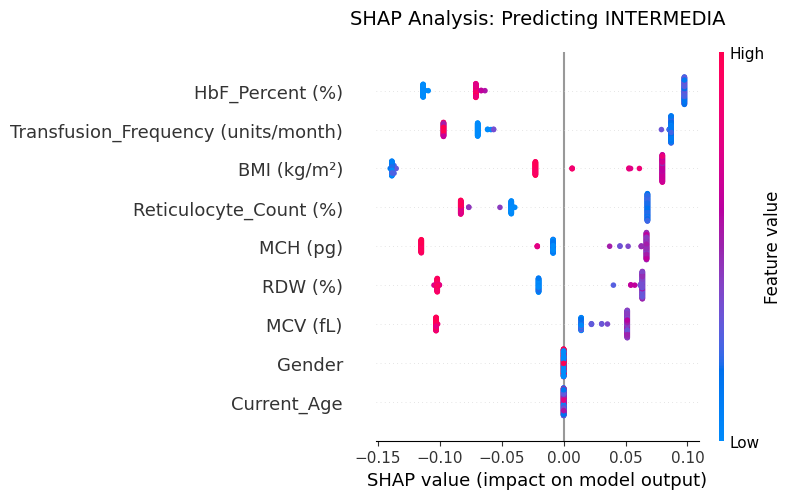

Generating SHAP plot for predicting: Major


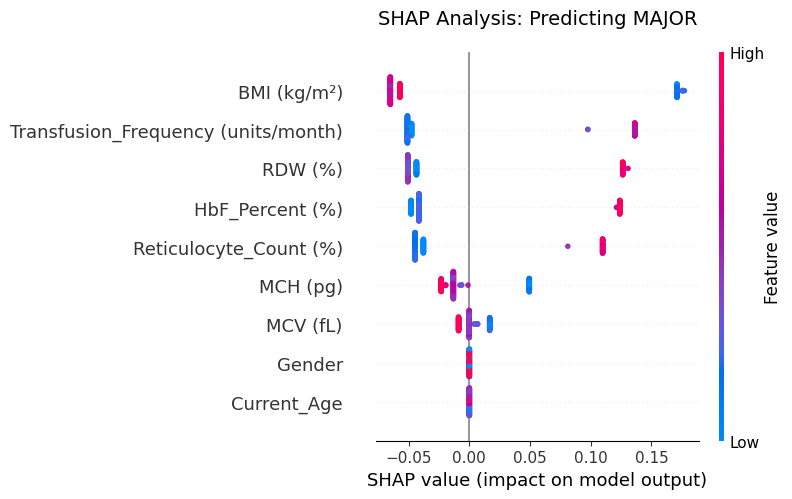

Generating SHAP plot for predicting: Minor


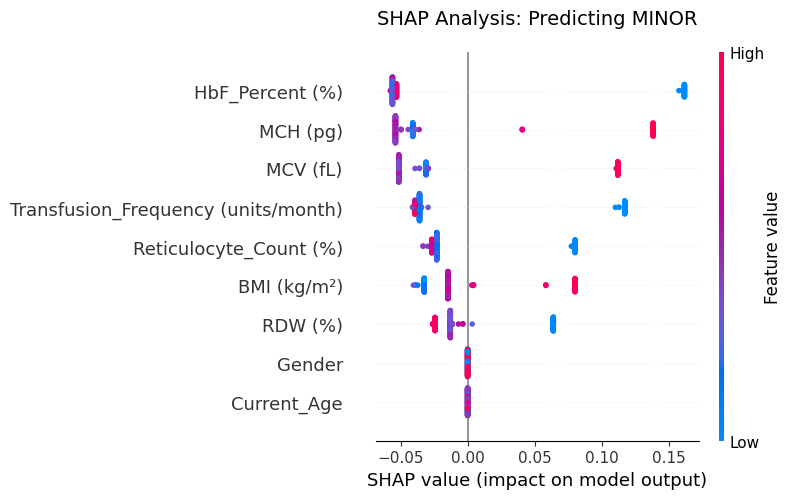

In [ ]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import warnings

warnings.filterwarnings('ignore')

def get_model_and_data_for_shap_bangladesh(df_name, df_original):
    df = df_original.copy()

    # Drop 'Patient_ID'
    if 'Patient_ID' in df.columns:
        df = df.drop(columns=['Patient_ID'])

    features_to_keep = [
        'Current_Age', 'Gender', 'BMI (kg/m²)', 'MCV (fL)', 'MCH (pg)', 'RDW (%)',
        'Reticulocyte_Count (%)', 'HbF_Percent (%)', 'Transfusion_Frequency (units/month)'
    ]
    target_column = 'Thalassemia_Type'

    all_required_cols = features_to_keep + [target_column]
    missing_cols = [col for col in all_required_cols if col not in df.columns]
    if missing_cols:
        print(f"Error: Missing required columns in {df_name}: {missing_cols}. Skipping SHAP analysis.")
        return None, None, None, None

    df = df[all_required_cols].copy()

    # Encode categorical features
    categorical_features = ['Gender']
    for col in categorical_features:
        if col in df.columns:
            le_feature = LabelEncoder()
            df[col] = le_feature.fit_transform(df[col].astype(str))

    # Convert numerical features to numeric, coercing errors to NaN
    numerical_features = [col for col in features_to_keep if col not in categorical_features]
    for col in numerical_features:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.dropna(subset=features_to_keep + [target_column])

    if df.empty or len(df) < 10:
        print(f"DataFrame {df_name} is empty or has too few samples after preprocessing. Skipping SHAP analysis.")
        return None, None, None, None

    # Encode target column 'Thalassemia_Type'
    le_thalassemia = LabelEncoder()
    df['Thalassemia_Type_encoded'] = le_thalassemia.fit_transform(df[target_column])

    X = df[features_to_keep]
    y = df['Thalassemia_Type_encoded']

    if len(y.unique()) < 2:
        print(f"Only one class present for target '{target_column}' in {df_name}. Cannot perform SHAP analysis.")
        return None, None, None, None

    # Split data into training and testing sets with stratification
    try:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    except ValueError:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=None)

    # Train a RandomForestClassifier for SHAP analysis
    rf_model = RandomForestClassifier(random_state=42)
    rf_model.fit(X_train, y_train)

    return rf_model, X_test, y_test, le_thalassemia

# --- SHAP analysis for Thalassemia_Bangladesh_dataset_df ---
print("\n--- Generating SHAP plots for Thalassemia_Bangladesh_dataset_df ---")
if 'Thalassemia_Bangladesh_dataset_df' in dataframes:
    model_bangladesh, X_test_bangladesh, y_test_bangladesh, le_bangladesh = get_model_and_data_for_shap_bangladesh('Thalassemia_Bangladesh_dataset_df', dataframes['Thalassemia_Bangladesh_dataset_df'])

    if model_bangladesh is not None:
        explainer = shap.TreeExplainer(model_bangladesh)
        # shap_values will be a list of arrays for multi-class classification
        # where each array corresponds to a class (n_samples, n_features)
        # OR a single 3D array (n_samples, n_features, n_classes).
        # The kernel state indicated a single 3D array, so we slice accordingly.
        shap_values = explainer.shap_values(X_test_bangladesh)

        for class_index, class_name in enumerate(le_bangladesh.classes_):
            print(f"Generating SHAP plot for predicting: {class_name}")

            # Correctly extract SHAP values for the current class
            # If shap_values is a list, this would be shap_values[class_index]
            # If shap_values is a 3D numpy array (samples, features, classes),
            # it should be sliced as below.
            sv = shap_values[:, :, class_index] # Corrected slicing

            exp = shap.Explanation(
                values=sv,
                data=X_test_bangladesh.values,
                feature_names=X_test_bangladesh.columns.tolist(),
                base_values=explainer.expected_value[class_index]
            )

            plt.figure(figsize=(12, 8))
            shap.plots.beeswarm(exp, max_display=len(X_test_bangladesh.columns), show=False)
            plt.title(f"SHAP Analysis: Predicting {class_name.upper()}", fontsize=14, pad=20)
            plt.tight_layout()
            plt.show()
    else:
        print("Could not generate SHAP plots due to issues with model or data preparation.")
else:
    print("Thalassemia_Bangladesh_dataset_df not found in dataframes.")

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.preprocessing import LabelEncoder

# =====================================================
# LOAD + PREPROCESS SAME AS SHAP
# =====================================================

df = dataframes['Thalassemia_Bangladesh_dataset_df'].copy()

if 'Patient_ID' in df.columns:
    df = df.drop(columns=['Patient_ID'])

features_to_keep = [
    'Current_Age',
    'Gender',
    'BMI (kg/m²)',
    'MCV (fL)',
    'MCH (pg)',
    'RDW (%)',
    'Reticulocyte_Count (%)',
    'HbF_Percent (%)',
    'Transfusion_Frequency (units/month)'
]

target_column = 'Thalassemia_Type'

df = df[features_to_keep + [target_column]].copy()

# Encode gender
le_gender = LabelEncoder()
df['Gender'] = le_gender.fit_transform(df['Gender'].astype(str))

# Numeric conversion
for col in features_to_keep:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)

# =====================================================
# MEAN + 95% CI
# =====================================================

results = []

for disease in sorted(df[target_column].unique()):

    subset = df[df[target_column] == disease]

    for feature in features_to_keep:

        values = subset[feature].dropna()

        n = len(values)

        mean = values.mean()
        sd = values.std(ddof=1)

        if n > 1:
            ci_low, ci_high = stats.t.interval(
                confidence=0.95,
                df=n-1,
                loc=mean,
                scale=stats.sem(values)
            )
        else:
            ci_low = np.nan
            ci_high = np.nan

        results.append({
            "Group": disease,
            "Feature": feature,
            "N": n,
            "Mean": round(mean, 3),
            "CI Lower": round(ci_low, 3),
            "CI Upper": round(ci_high, 3)
        })

results_df = pd.DataFrame(results)

print(results_df)

# optional export
results_df.to_csv(
    "Bangladesh_Mean_95CI.csv",
    index=False
)

print("\nSaved: Bangladesh_Mean_95CI.csv")

         Group                              Feature    N    Mean  CI Lower  \
0   Intermedia                          Current_Age  302  27.533    26.517   
1   Intermedia                               Gender  302   0.526     0.470   
2   Intermedia                          BMI (kg/m²)  302  20.897    20.733   
3   Intermedia                             MCV (fL)  302  69.361    69.009   
4   Intermedia                             MCH (pg)  302  22.271    22.090   
5   Intermedia                              RDW (%)  302  16.699    16.475   
6   Intermedia               Reticulocyte_Count (%)  302   3.185     3.132   
7   Intermedia                      HbF_Percent (%)  302  11.626    11.309   
8   Intermedia  Transfusion_Frequency (units/month)  302   1.325     1.285   
9        Major                          Current_Age  163  14.632    13.509   
10       Major                               Gender  163   0.509     0.432   
11       Major                          BMI (kg/m²)  163  12.378

Exploratory SHAP analysis revealed non-biological feature distributions and unusually narrow 95% Confidence Intervals (e.g., in BMI and Transfusion Frequency). While this may reflect extreme 'over-restriction' in the original study’s sampling protocol, the lack of biological variance limits its utility for cross-population ML generalizability

In [ ]:
wb_df.head()

,Sl No,Age,Gender,Religion,Present District,HbA0,HbA2,HbF,S-Window,Unknown,RBC,HB,MCV,MCH,MCHC,RDWcv,Weekness,Jaundice,Diagnosis,Age_Years
0,1,14 Yrs 11 month,Female,Hinduism,Howrah,86.2,2.9,0.3,0.0,0.0,4.81,13.2,86.7,28.8,33.0,13.8,No,No,Normal,14.916667
1,2,16 Yrs 0 month,Female,Hinduism,Kolkata,86.4,4.8,0.4,0.0,0.0,4.18,10.9,78.9,26.1,33.0,14.6,No,No,Beta Thalassaemia carrier,16.000000
2,3,16 Yrs 2 month,Male,Hinduism,Hooghly,87.3,3.2,0.5,0.0,0.0,5.31,13.6,87.0,25.6,29.4,13.7,No,No,Normal,16.166667
3,4,21 Yrs 0 month,Female,Hinduism,South 24-Parganas,87.9,2.8,0.2,0.0,0.0,4.64,11.5,78.7,44.8,31.5,14.5,No,No,Normal,21.000000
4,5,35 Yrs 3 month,Male,Hinduism,Midnapore (East),84.3,2.8,0.2,0.0,0.0,5.50,14.0,69.7,21.5,30.9,16.5,No,No,Normal,35.250000


In [ ]:
import pandas as pd
import numpy as np
import warnings
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

warnings.filterwarnings('ignore')


def convert_age_to_years(age_str):

    if pd.isna(age_str) or not isinstance(age_str, str):
        return np.nan

    years = re.search(r'(\d+)\s*Yrs?', age_str)
    months = re.search(r'(\d+)\s*month', age_str)

    y = int(years.group(1)) if years else 0
    m = int(months.group(1)) if months else 0

    return ((y * 12) + m) / 12.0


def train_and_evaluate_westbengal_models(df_name, df_original):

    print(f"\n--- Processing {df_name} ---")

    df = df_original.copy()

    # Age conversion
    if 'Age_Years' not in df.columns:
        df['Age_Years'] = df['Age'].apply(convert_age_to_years)

    # Clean Diagnosis
    df['Diagnosis'] = (
        df['Diagnosis']
        .astype(str)
        .str.strip()
        .replace(['Normal', 'Normal ', 'Normal  '], 'Normal')
    )

    # Define the core target classes mentioned by the user
    main_target_classes = [
        'Normal',
        'Beta Thalassaemia carrier',
        'HbE carrier'
    ]

    # Assign 'Other' to any diagnosis not in the main target classes
    # This creates the potential for a 4th class if other diagnosis values exist
    df.loc[~df['Diagnosis'].isin(main_target_classes), 'Diagnosis'] = 'Other'

    # Now define the full set of target classes for classification
    # This will include 'Other' if it was created.
    target_classes = sorted(list(df['Diagnosis'].unique())) # Sort to ensure consistent encoding

    # Ensure we only keep rows with these target classes
    df = df[df['Diagnosis'].isin(target_classes)].copy()

    print(f"Classes for classification: {target_classes}")

    # Features
    features = [
        'Age_Years', 'Gender', 'HB',
        'RBC', 'MCV', 'MCH',
        'MCHC', 'RDWcv'
    ]

    target = 'Diagnosis'

    # Keep needed columns
    df = df[features + [target]].copy()

    # Encode Gender
    le_gender = LabelEncoder()
    df['Gender'] = le_gender.fit_transform(df['Gender'].astype(str))

    # Numeric conversion
    for col in features:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Drop NaNs
    df.dropna(inplace=True)

    # Encode target
    le_target = LabelEncoder()
    df['Target'] = le_target.fit_transform(df[target])

    X = df[features]
    y = df['Target']

    # Check if there are enough samples and classes after preprocessing
    if len(y.unique()) < 2 or len(df) < 10: # Ensure enough data for splitting and training
        print(f"DataFrame {df_name} is empty or has too few samples or classes after preprocessing ({df.shape[0]} rows, {len(y.unique())} classes). Skipping model training.")
        return


    # Train-test split
    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.3,
            random_state=42,
            stratify=y
        )
    except ValueError as e:
        print(f"Could not stratify due to: {e}. Attempting without stratification.")
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=None)

    # Models
    models = {
        'Logistic Regression': LogisticRegression(
            random_state=42,
            solver='liblinear',
            multi_class='ovr'
        ),

        'Random Forest': RandomForestClassifier(
            random_state=42
        ),

        'XGBoost': XGBClassifier(
            use_label_encoder=False,
            eval_metric='mlogloss',
            random_state=42
        )
    }

    results = []

    # Train + Evaluate
    for model_name, model in models.items():

        if model_name == 'Logistic Regression':

            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_test_scaled)
            y_prob = model.predict_proba(X_test_scaled)

        else:

            model.fit(X_train, y_train)

            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)

        accuracy = accuracy_score(y_test, y_pred)

        f1 = f1_score(
            y_test,
            y_pred,
            average='weighted'
        )

        auc = roc_auc_score(
            y_test,
            y_prob,
            multi_class='ovr',
            average='weighted'
        )

        results.append({
            'Model': model_name,
            'Accuracy': round(accuracy, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4)
        })

    # Results table
    results_df = pd.DataFrame(results)

    print("\n=== Model Performance Summary ===")
    print(results_df)


# Execute
if 'westbengal_df' in dataframes:

    train_and_evaluate_westbengal_models(
        'westbengal_df',
        dataframes['westbengal_df']
    )

else:
    print("westbengal_df not found in dataframes.")


--- Processing westbengal_df ---
Classes for classification: ['Beta Thalassaemia carrier', 'HbE carrier', 'Normal', 'Other']

=== Model Performance Summary ===
                 Model  Accuracy  F1 Score     AUC
0  Logistic Regression    0.9156    0.8903  0.8857
1        Random Forest    0.9237    0.9041  0.8983
2              XGBoost    0.9222    0.9084  0.9083


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE # The magic ingredient
import warnings
import re

warnings.filterwarnings('ignore')

def convert_age_to_years(age_str):
    if pd.isna(age_str) or not isinstance(age_str, str):
        return np.nan
    years = re.search(r'(\d+)\s*Yrs?', age_str)
    months = re.search(r'(\d+)\s*month', age_str)
    y = int(years.group(1)) if years else 0
    m = int(months.group(1)) if months else 0
    return (y * 12 + m) / 12.0

def train_and_evaluate_westbengal_models_with_smote(df_name, df_original):
    print(f"--- Processing {df_name} with SMOTE for Thalassemia Prediction ---")
    df = df_original.copy()

    if 'Age_Years' not in df.columns:
        df['Age_Years'] = df['Age'].apply(convert_age_to_years)

    df['Diagnosis'] = df['Diagnosis'].astype(str).str.strip().replace(['Normal', 'Normal ', 'Normal  '], 'Normal')
    target_classes = ['Normal', 'Beta Thalassaemia carrier', 'HbE carrier']
    df = df[df['Diagnosis'].isin(target_classes)].copy()

    features_to_keep = ['Age_Years', 'Gender', 'HB', 'RBC', 'MCV', 'MCH', 'MCHC', 'RDWcv']
    target_column = 'Diagnosis'
    df = df[features_to_keep + [target_column]].dropna()
    le_gender = LabelEncoder()
    df['Gender'] = le_gender.fit_transform(df['Gender'].astype(str))

    le_diagnosis = LabelEncoder()
    df['Diagnosis_encoded'] = le_diagnosis.fit_transform(df[target_column])

    X = df[features_to_keep]
    y = df['Diagnosis_encoded']

    # 1. Split FIRST (Never SMOTE before splitting, or you leak data)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    # 2. Apply SMOTE to the TRAINING set only
    # This creates synthetic samples for 'HbE carrier' and 'Beta Thal carrier'
    print(f"Original training class distribution: {np.bincount(y_train)}")
    sm = SMOTE(random_state=42)
    X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
    print(f"Resampled training class distribution: {np.bincount(y_train_res)}")

    models = {
        "Logistic Regression": LogisticRegression(random_state=42, solver='liblinear', multi_class='ovr'),
        "RandomForest Classifier": RandomForestClassifier(random_state=42),
        "XGBoost Classifier": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
    }

    for model_name, model in models.items():
        print(f"\n--- Evaluating {model_name} (Trained on SMOTE Data) ---")

        if model_name == "Logistic Regression":
            scaler = StandardScaler()
            # Scale based on the resampled training data
            X_train_scaled = scaler.fit_transform(X_train_res)
            X_test_scaled = scaler.transform(X_test)
            model.fit(X_train_scaled, y_train_res)
            y_pred = model.predict(X_test_scaled)
        else:
            model.fit(X_train_res, y_train_res)
            y_pred = model.predict(X_test)

        print(classification_report(y_test, y_pred, target_names=le_diagnosis.classes_))

# --- Execute ---
if 'westbengal_df' in dataframes:
    train_and_evaluate_westbengal_models_with_smote('westbengal_df', dataframes['westbengal_df'])

--- Processing westbengal_df with SMOTE for Thalassemia Prediction ---
Original training class distribution: [ 393  382 8244]
Resampled training class distribution: [8244 8244 8244]

--- Evaluating Logistic Regression (Trained on SMOTE Data) ---
                           precision    recall  f1-score   support

Beta Thalassaemia carrier       0.35      0.85      0.50       169
              HbE carrier       0.14      0.53      0.23       164
                   Normal       0.98      0.79      0.88      3533

                 accuracy                           0.78      3866
                macro avg       0.49      0.72      0.53      3866
             weighted avg       0.92      0.78      0.83      3866


--- Evaluating RandomForest Classifier (Trained on SMOTE Data) ---
                           precision    recall  f1-score   support

Beta Thalassaemia carrier       0.50      0.77      0.60       169
              HbE carrier       0.23      0.40      0.29       164
            

In [ ]:
import pandas as pd
import numpy as np
import re
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

warnings.filterwarnings('ignore')

def convert_age_to_years(age_str):
    if pd.isna(age_str) or not isinstance(age_str, str):
        return np.nan

    years = re.search(r'(\d+)\s*Yrs?', age_str)
    months = re.search(r'(\d+)\s*month', age_str)

    y = int(years.group(1)) if years else 0
    m = int(months.group(1)) if months else 0

    return ((y * 12) + m) / 12.0


def train_and_evaluate_westbengal_models(df_name, df_original):

    df = df_original.copy()

    if 'Age_Years' not in df.columns:
        df['Age_Years'] = df['Age'].apply(convert_age_to_years)

    df['Diagnosis'] = (
        df['Diagnosis']
        .astype(str)
        .str.strip()
        .replace(['Normal', 'Normal ', 'Normal  '], 'Normal')
    )

    target_classes = [
        'Normal',
        'Beta Thalassaemia carrier',
        'HbE carrier'
    ]

    df = df[df['Diagnosis'].isin(target_classes)].copy()

    features = [
        'Age_Years', 'Gender', 'HB',
        'RBC', 'MCV', 'MCH', 'MCHC', 'RDWcv'
    ]

    target = 'Diagnosis'

    df = df[features + [target]].copy()

    # Encode Gender
    le_gender = LabelEncoder()
    df['Gender'] = le_gender.fit_transform(df['Gender'].astype(str))

    # Numeric conversion
    for col in features:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Drop NaNs
    df = df.dropna()

    # Encode target
    le_target = LabelEncoder()
    df['Target'] = le_target.fit_transform(df[target])

    X = df[features]
    y = df['Target']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.3,
        random_state=42,
        stratify=y
    )

    models = {
        "Logistic Regression": LogisticRegression(
            random_state=42,
            solver='liblinear',
            multi_class='ovr'
        ),
        "Random Forest": RandomForestClassifier(
            random_state=42
        ),
        "XGBoost": XGBClassifier(
            use_label_encoder=False,
            eval_metric='mlogloss',
            random_state=42
        )
    }

    results = []

    for name, model in models.items():

        if name == "Logistic Regression":

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_test_scaled)
            y_prob = model.predict_proba(X_test_scaled)
        else:
            model.fit(X_train, y_train)

            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)

        results.append({
            "Model": name,
            "Accuracy": round(accuracy_score(y_test, y_pred), 4),
            "F1 Score": round(f1_score(y_test, y_pred, average='weighted'), 4),
            "AUC": round(
                roc_auc_score(
                    y_test,
                    y_prob,
                    multi_class='ovr',
                    average='weighted'
                ),
                4
            )
        })

    results_df = pd.DataFrame(results)

    print(f"\n=== {df_name} Model Performance ===")
    print(results_df)
if 'westbengal_df' in dataframes:
    train_and_evaluate_westbengal_models(
        'westbengal_df',
        dataframes['westbengal_df']
    )
else:
    print("westbengal_df not found.")


=== westbengal_df Model Performance ===
                 Model  Accuracy  F1 Score     AUC
0  Logistic Regression    0.9252    0.9034  0.8940
1        Random Forest    0.9327    0.9170  0.9101
2              XGBoost    0.9330    0.9223  0.9145


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def evaluate_westbengal_indices(df_original):
    df = df_original.copy()
    target_classes = ['Normal', 'Beta Thalassaemia carrier', 'HbE carrier']
    df = df[df['Diagnosis'].isin(target_classes)].copy()

    # 1. Correct Mathematical Formulas (with small epsilon to prevent division by zero)
    indices = {
        "Mentzer": lambda d: d['MCV'] / (d['RBC'] + 1e-9),
        "England & Fraser": lambda d: d['MCV'] - (5 * d['HB']) - d['RBC'] - 3.4,
        "Srivastava": lambda d: d['MCH'] / (d['RBC'] + 1e-9),
        "Green & King": lambda d: (d['MCV']**2 * d['RDWcv']) / (d['HB'] * 10 + 1e-9),
        "RDWI": lambda d: (d['MCV'] * d['RDWcv']) / (d['RBC'] + 1e-9),
        "Shine-Lal": lambda d: (d['MCV']**2 * d['MCH']) / 100
    }

    # Standard Clinical Thresholds
    thresholds = {
        "Mentzer": 13,
        "England & Fraser": 0,
        "Srivastava": 3.8,
        "Green & King": 65,
        "RDWI": 220,
        "Shine-Lal": 1530
    }

    results = []

    for disease in ['Beta Thalassaemia carrier', 'HbE carrier']:
        sub = df[df['Diagnosis'].isin(['Normal', disease])].copy()

        # Explicit mapping (Normal=0, Disease=1) to prevent alphabetical auto-sorting bugs
        y_true = sub['Diagnosis'].apply(lambda x: 1 if x == disease else 0).values

        for name, formula in indices.items():
            score = formula(sub).values

            # Handle calculation direction cleanly for predictions and AUC
            if name in ["Green & King", "RDWI"]:
                y_pred = (score > thresholds[name]).astype(int)
                auc_score = score
            else:
                y_pred = (score < thresholds[name]).astype(int)
                auc_score = -score

            results.append({
                "Target": disease,
                "Index": name,
                "Accuracy": accuracy_score(y_true, y_pred),
                "F1-Score": f1_score(y_true, y_pred, zero_division=0),
                "AUC": roc_auc_score(y_true, auc_score)
            })

    return pd.DataFrame(results)


# =====================================================================
# EXECUTION BLOCK (Make sure df_original points to your loaded data!)
# =====================================================================

# 1. Generate the results by calling the function and assigning it to the variable
wb_index_results = evaluate_westbengal_indices(dataframes['westbengal_df'])

# 2. Now that the variable is defined, display it sorted cleanly
display(wb_index_results.sort_values(by=['Target', 'AUC'], ascending=[True, False]))

,Target,Index,Accuracy,F1-Score,AUC
5,Beta Thalassaemia carrier,Shine-Lal,0.869826,0.400597,0.963827
2,Beta Thalassaemia carrier,Srivastava,0.958283,0.475025,0.920553
0,Beta Thalassaemia carrier,Mentzer,0.959660,0.530189,0.918084
1,Beta Thalassaemia carrier,England & Fraser,0.934548,0.254613,0.809397
3,Beta Thalassaemia carrier,Green & King,0.045606,0.087091,0.240701
4,Beta Thalassaemia carrier,RDWI,0.121426,0.042549,0.190685
11,HbE carrier,Shine-Lal,0.850839,0.239139,0.833961
6,HbE carrier,Mentzer,0.941277,0.097257,0.769385
8,HbE carrier,Srivastava,0.942331,0.055777,0.747610
7,HbE carrier,England & Fraser,0.929840,0.130653,0.708286


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def run_ml_comparison_analogue(df_original):
    df = df_original.copy()

    # 1. Preprocessing (Standardizing for West Bengal columns)
    df['Diagnosis'] = df['Diagnosis'].astype(str).str.strip().replace(['Normal', 'Normal ', 'Normal  '], 'Normal')

    # Feature Selection
    features = ['Age_Years', 'Gender', 'HB', 'RBC', 'MCV', 'MCH', 'MCHC', 'RDWcv']

    # Ensure Age_Years exists
    if 'Age_Years' not in df.columns:
        # Re-using your conversion logic if necessary
        df['Age_Years'] = pd.to_numeric(df['Age'], errors='coerce')

    le_gender = LabelEncoder()
    df['Gender'] = le_gender.fit_transform(df['Gender'].astype(str))

    for col in features:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    df.dropna(subset=features + ['Diagnosis'], inplace=True)

    # Define the two comparison tasks
    scenarios = [
        ('Normal', 'Beta Thalassaemia carrier'),
        ('Normal', 'HbE carrier')
    ]

    ml_results = []

    for control, disease in scenarios:
        # Filter for binary task
        sub_df = df[df['Diagnosis'].isin([control, disease])].copy()
        le_target = LabelEncoder()
        sub_df['Target_Enc'] = le_target.fit_transform(sub_df['Diagnosis']) # 0=Normal, 1=Disease

        X = sub_df[features]
        y = sub_df['Target_Enc']

        kf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

        models = {
            'LogReg': LogisticRegression(solver='liblinear', random_state=42),
            'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
            'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)
        }

        for name, model in models.items():
            fold_accuracies = []
            fold_f1_scores = []
            fold_aucs = []

            for train_index, test_index in kf.split(X, y):
                X_train, X_test = X.iloc[train_index], X.iloc[test_index]
                y_train, y_test = y.iloc[train_index], y.iloc[test_index]

                # Scale only for LogReg
                if name == 'LogReg':
                    scaler = StandardScaler()
                    X_tr = scaler.fit_transform(X_train)
                    X_ts = scaler.transform(X_test)
                else:
                    X_tr, X_ts = X_train, X_test

                model.fit(X_tr, y_train)
                y_pred = model.predict(X_ts)
                y_prob = model.predict_proba(X_ts)[:, 1]

                fold_accuracies.append(accuracy_score(y_test, y_pred))
                fold_f1_scores.append(f1_score(y_test, y_pred))
                fold_aucs.append(roc_auc_score(y_test, y_prob))

            ml_results.append({
                'Target': disease,
                'Model': name,
                'Accuracy': round(np.mean(fold_accuracies), 6),
                'F1-Score': round(np.mean(fold_f1_scores), 6),
                'AUC': round(np.mean(fold_aucs), 6)
            })

    return pd.DataFrame(ml_results)

# Execute and Display
ml_analogue_table = run_ml_comparison_analogue(dataframes['westbengal_df'])
print("\n--- ML Performance Analogue (Normal vs. Carriers) ---")
print(ml_analogue_table.to_string(index=False))



--- ML Performance Analogue (Normal vs. Carriers) ---
                   Target         Model  Accuracy  F1-Score      AUC
Beta Thalassaemia carrier        LogReg  0.969285  0.984025 0.964625
Beta Thalassaemia carrier Random Forest  0.974552  0.986751 0.960244
Beta Thalassaemia carrier       XGBoost  0.972283  0.985546 0.963690
              HbE carrier        LogReg  0.954394  0.976655 0.842104
              HbE carrier Random Forest  0.955449  0.977139 0.865029
              HbE carrier       XGBoost  0.952203  0.975360 0.862854


--- Generating 3 Separate SHAP Plots for westbengal_df ---
Plotting Class 0: Beta Thalassaemia carrier


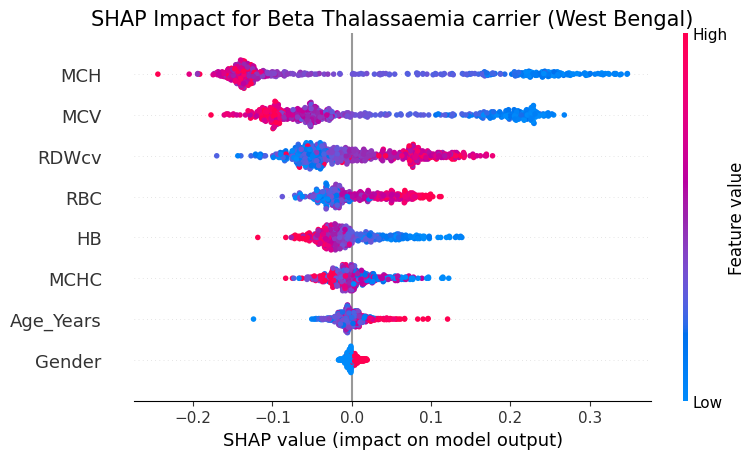

Plotting Class 1: HbE carrier


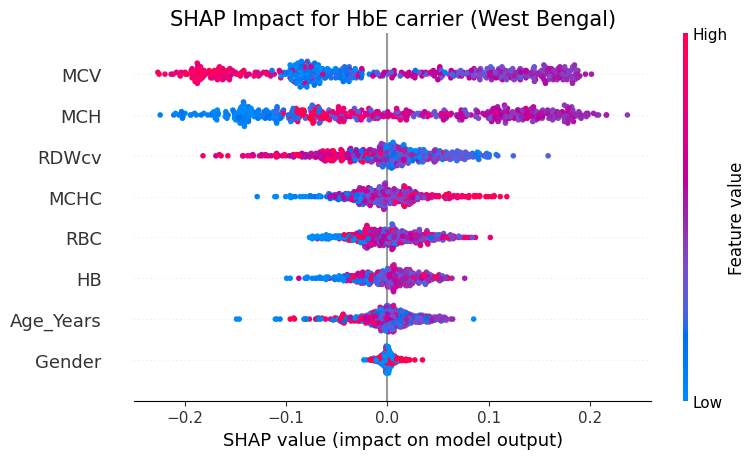

Plotting Class 2: Normal


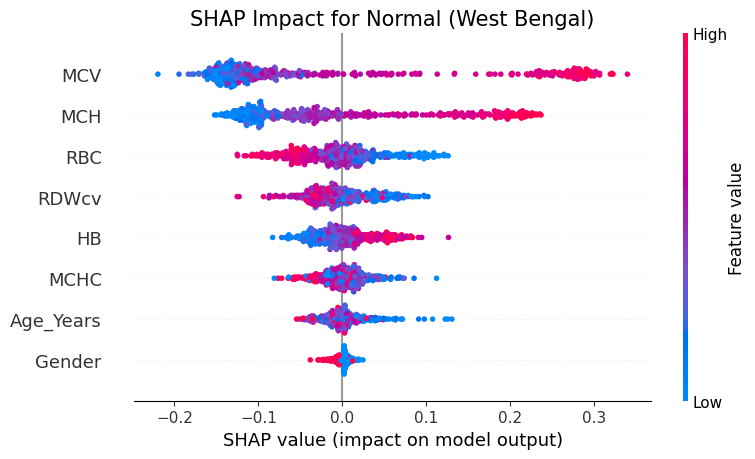

In [ ]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import warnings
import re

warnings.filterwarnings('ignore')
def generate_three_separate_shap_plots(df_name, df_original):
    print(f"--- Generating 3 Separate SHAP Plots for {df_name} ---")
    df = df_original.copy()

    if 'Age_Years' not in df.columns:
        df['Age_Years'] = df['Age'].apply(convert_age_to_years)

    df['Diagnosis'] = df['Diagnosis'].astype(str).str.strip().replace(['Normal', 'Normal ', 'Normal  '], 'Normal')
    target_classes = ['Normal', 'Beta Thalassaemia carrier', 'HbE carrier']
    df = df[df['Diagnosis'].isin(target_classes)].copy()
    df_normal = df[df['Diagnosis'] == 'Normal'].sample(n=min(len(df[df['Diagnosis'] == 'Normal']), 562), random_state=42)
    df_beta = df[df['Diagnosis'] == 'Beta Thalassaemia carrier']
    df_hbe = df[df['Diagnosis'] == 'HbE carrier']

    df_balanced = pd.concat([df_normal, df_beta, df_hbe]).sample(frac=1, random_state=42)

    features = ['Age_Years', 'Gender', 'HB', 'RBC', 'MCV', 'MCH', 'MCHC', 'RDWcv']
    df_balanced = df_balanced[features + ['Diagnosis']].dropna()
    df_balanced['Gender'] = LabelEncoder().fit_transform(df_balanced['Gender'].astype(str))

    le_diag = LabelEncoder()
    X = df_balanced[features]
    y = le_diag.fit_transform(df_balanced['Diagnosis'])

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)
    explainer = shap.TreeExplainer(rf_model)
    shap_results = explainer.shap_values(X_test)
    for class_index, class_name in enumerate(le_diag.classes_):
        print(f"Plotting Class {class_index}: {class_name}")
        if isinstance(shap_results, list):
            sv = shap_results[class_index]
        else:
            sv = shap_results[:, :, class_index]

        # Create the Explanation object
        exp = shap.Explanation(
            values=sv,
            data=X_test.values,
            feature_names=features,
            base_values=explainer.expected_value[class_index]
        )

        plt.figure(figsize=(10, 6))
        plt.title(f"SHAP Impact for {class_name} (West Bengal)", fontsize=15)
        shap.plots.beeswarm(exp, show=False)
        plt.tight_layout()
        plt.show() # This forces a separate window/output for each plot

# Execute
if 'westbengal_df' in dataframes:
    generate_three_separate_shap_plots('westbengal_df', dataframes['westbengal_df'])

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def generate_ida_btt_correlations(df_original):
    df = df_original.copy()
    df = df.drop(columns=['ID', 'pname'], errors='ignore')
    classes = {0: "Iron Deficiency Anemia (IDA)", 1: "Beta Thalassemia Trait (BTT)"}

    params = ['CBC_MCV', 'CBC_MCH', 'CBC_RDW', 'CBC_RBC', 'Hb', 'Platelets']
    available_params = [p for p in params if p in df.columns]

    for class_val, class_name in classes.items():
        subset = df[df['Class'] == class_val][available_params]

        if len(subset) < 3:
            print(f"Skipping {class_name}: Not enough samples.")
            continue

        # Calculate Pearson Correlation
        corr_matrix = subset.corr(method='pearson')

        # --- Print Text Matrix ---
        print(f"\n{'='*20} {class_name} Correlation Matrix {'='*20}")
        print(corr_matrix.round(3).to_string())
        plt.figure(figsize=(10, 8))
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

        sns.heatmap(corr_matrix,
                    mask=mask,
                    annot=True,
                    fmt=".2f",
                    cmap='coolwarm',
                    center=0,
                    vmin=-1, vmax=1,
                    linewidths=.5)

        plt.title(f"Pearson Correlation: {class_name}", fontsize=15, pad=15)
        plt.show()

if 'IDA_BTT_df' in dataframes:
    generate_ida_btt_correlations(dataframes['IDA_BTT_df'])

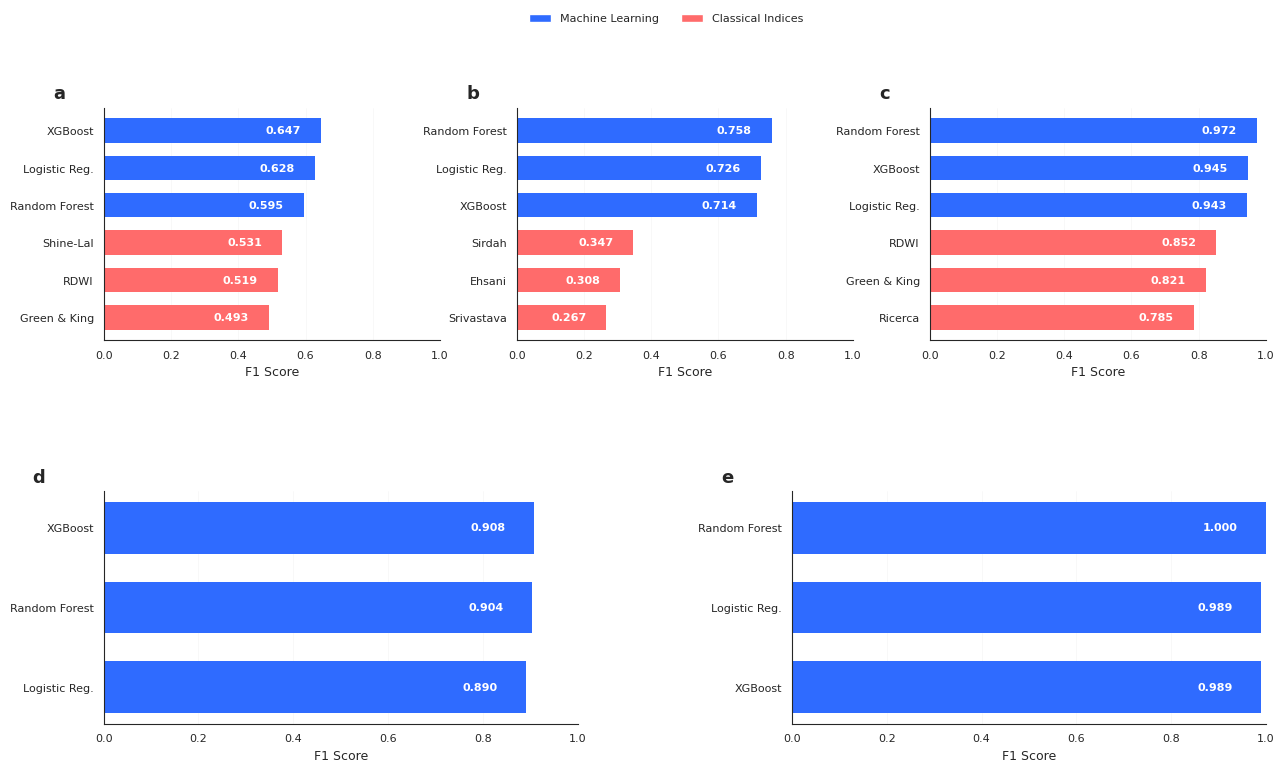

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

# =============================================================================
# STYLE
# =============================================================================

sns.set_style("white")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.linewidth": 0.8,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

ML_COLOR = "#2F6BFF"        # electric blue
CLASSICAL_COLOR = "#FF6B6B" # coral red

# =============================================================================
# FIGURE
# =============================================================================

fig = plt.figure(figsize=(15, 8))

gs = GridSpec(
    2,
    9,
    figure=fig,
    hspace=0.65,
    wspace=1.25
)

# Top row
ax_a = fig.add_subplot(gs[0, 0:3])
ax_b = fig.add_subplot(gs[0, 3:6])
ax_c = fig.add_subplot(gs[0, 6:9])

# Bottom row
ax_d = fig.add_subplot(gs[1, 0:4])
ax_e = fig.add_subplot(gs[1, 5:9])

# =============================================================================
# DRAW FUNCTION
# =============================================================================

def draw_panel(
    ax,
    methods,
    scores,
    colors,
    panel_letter,
    xlabel
):

    y = np.arange(len(methods))

    bars = ax.barh(
        y,
        scores,
        color=colors,
        edgecolor="none",
        height=0.65
    )

    ax.set_yticks(y)
    ax.set_yticklabels(methods)

    ax.set_xlim(0, 1)

    ax.set_xticks(
        np.arange(0, 1.01, 0.2)
    )

    ax.set_xlabel(xlabel)

    ax.grid(
        axis="x",
        alpha=0.15,
        linewidth=0.6
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.invert_yaxis()

    for bar, val in zip(bars, scores):

        x_text = max(val - 0.06, 0.03)

        ax.text(
            x_text,
            bar.get_y() + bar.get_height()/2,
            f"{val:.3f}",
            ha="right",
            va="center",
            color="white",
            fontsize=8,
            fontweight="bold"
        )

    ax.text(
        -0.15,
        1.04,
        panel_letter,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold"
    )

# =============================================================================
# PANEL A
# =============================================================================

# Data for Panel A
methods_a = [
    "Random Forest",
    "XGBoost",
    "Logistic Reg.",
    "RDWI",
    "Shine-Lal",
    "Green & King"
]
scores_a = [
    0.5954,
    0.6471,
    0.6280,
    0.5186,
    0.5311,
    0.4927
]
colors_a = [
    ML_COLOR,
    ML_COLOR,
    ML_COLOR,
    CLASSICAL_COLOR,
    CLASSICAL_COLOR,
    CLASSICAL_COLOR
]

# Combine and sort data for Panel A
combined_a = sorted(zip(scores_a, methods_a, colors_a), key=lambda x: x[0], reverse=True)
scores_a_sorted, methods_a_sorted, colors_a_sorted = zip(*combined_a)

draw_panel(
    ax_a,
    methods=list(methods_a_sorted),
    scores=list(scores_a_sorted),
    colors=list(colors_a_sorted),
    panel_letter="a",
    xlabel="F1 Score"
)

# =============================================================================
# PANEL B
# =============================================================================

# Data for Panel B
methods_b = [
    "Random Forest",
    "XGBoost",
    "Sirdah",
    "Ehsani",
    "Srivastava",
    "Logistic Reg."
]
scores_b = [
    0.7577,
    0.7137,
    0.3473,
    0.3085,
    0.2671,
    0.7262
]
colors_b = [
    ML_COLOR,
    ML_COLOR,
    CLASSICAL_COLOR,
    CLASSICAL_COLOR,
    CLASSICAL_COLOR,
    ML_COLOR
]

# Combine and sort data for Panel B
combined_b = sorted(zip(scores_b, methods_b, colors_b), key=lambda x: x[0], reverse=True)
scores_b_sorted, methods_b_sorted, colors_b_sorted = zip(*combined_b)

draw_panel(
    ax_b,
    methods=list(methods_b_sorted),
    scores=list(scores_b_sorted),
    colors=list(colors_b_sorted),
    panel_letter="b",
    xlabel="F1 Score"
)

# =============================================================================
# PANEL C
# =============================================================================

# Data for Panel C
methods_c = [
    "Logistic Reg.",
    "Green & King",
    "XGBoost",
    "RDWI",
    "Random Forest",
    "Ricerca"
]
scores_c = [
    0.9427,
    0.8205,
    0.9449,
    0.8524,
    0.9724,
    0.7850
]
colors_c = [
    ML_COLOR,
    CLASSICAL_COLOR,
    ML_COLOR,
    CLASSICAL_COLOR,
    ML_COLOR,
    CLASSICAL_COLOR
]

# Combine and sort data for Panel C
combined_c = sorted(zip(scores_c, methods_c, colors_c), key=lambda x: x[0], reverse=True)
scores_c_sorted, methods_c_sorted, colors_c_sorted = zip(*combined_c)

draw_panel(
    ax_c,
    methods=list(methods_c_sorted),
    scores=list(scores_c_sorted),
    colors=list(colors_c_sorted),
    panel_letter="c",
    xlabel="F1 Score"
)

# =============================================================================
# PANEL D (WEST BENGAL)
# F1 SCORE
# =============================================================================

draw_panel(
    ax_d,
    methods=[
        "XGBoost",
        "Random Forest",
        "Logistic Reg."
    ],
    scores=[
        0.9084,
        0.9041,
        0.8903
    ],
    colors=[
        ML_COLOR,
        ML_COLOR,
        ML_COLOR
    ],
    panel_letter="d",
    xlabel="F1 Score"
)

# =============================================================================
# PANEL E (BANGLADESH)
# F1 SCORE
# =============================================================================

draw_panel(
    ax_e,
    methods=[
        "Random Forest",
        "Logistic Reg.",
        "XGBoost"
    ],
    scores=[
        1.0000,
        0.9892,
        0.9892
    ],
    colors=[
        ML_COLOR,
        ML_COLOR,
        ML_COLOR
    ],
    panel_letter="e",
    xlabel="F1 Score"
)

# =============================================================================
# LEGEND
# =============================================================================

legend_elements = [
    Patch(
        facecolor=ML_COLOR,
        label="Machine Learning"
    ),
    Patch(
        facecolor=CLASSICAL_COLOR,
        label="Classical Indices"
    )
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01)
)

# =============================================================================
# SAVE
# =============================================================================

plt.savefig(
    "Figure1_Final.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure1_Final.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


Logistic Regression
F1 = 0.9784
AUC = 1.0000

Random Forest
F1 = 0.9837
AUC = 1.0000

XGBoost
F1 = 0.9731
AUC = 0.9979


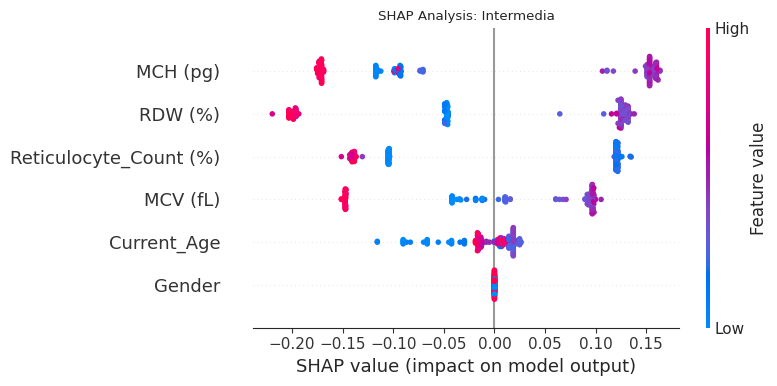

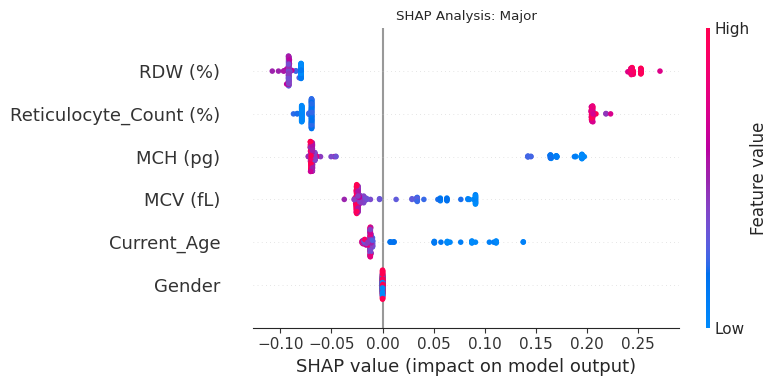

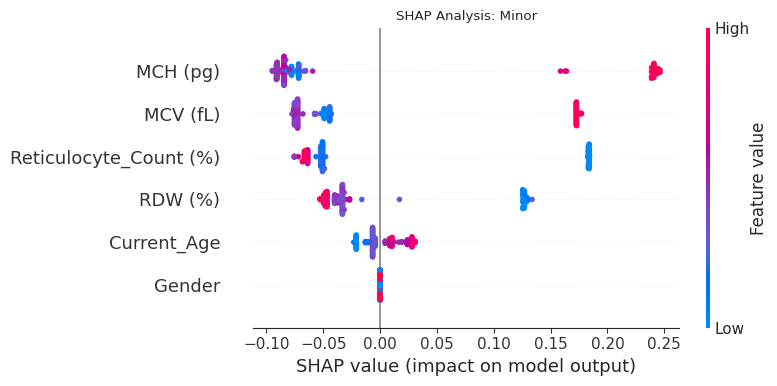

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, roc_auc_score
import shap
import matplotlib.pyplot as plt

df = dataframes['Thalassemia_Bangladesh_dataset_df'].copy()

if 'Patient_ID' in df.columns:
    df.drop(columns=['Patient_ID'], inplace=True)

# CBC-oriented feature set
features = [
    'Current_Age',
    'Gender',
    'MCV (fL)',
    'MCH (pg)',
    'RDW (%)',
    'Reticulocyte_Count (%)'
]

target = 'Thalassemia_Type'

# encode gender
le_gender = LabelEncoder()
df['Gender'] = le_gender.fit_transform(df['Gender'].astype(str))

# numeric conversion
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df[features + [target]].dropna()

# encode target
le_target = LabelEncoder()
y = le_target.fit_transform(df[target])

X = df[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(
        random_state=42,
        solver="liblinear",
        multi_class="ovr"
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="mlogloss"
    )
}

for name, model in models.items():

    if name == "Logistic Regression":

        scaler = StandardScaler()

        X_train_fit = scaler.fit_transform(X_train)
        X_test_fit = scaler.transform(X_test)

    else:

        X_train_fit = X_train
        X_test_fit = X_test

    model.fit(X_train_fit, y_train)

    pred = model.predict(X_test_fit)
    prob = model.predict_proba(X_test_fit)

    f1 = f1_score(y_test, pred, average='weighted')
    auc = roc_auc_score(
        y_test,
        prob,
        multi_class='ovr',
        average='weighted'
    )

    print(f"\n{name}")
    print(f"F1 = {f1:.4f}")
    print(f"AUC = {auc:.4f}")

# SHAP using RF
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

for i, cls in enumerate(le_target.classes_):

    exp = shap.Explanation(
        values=shap_values[:, :, i],
        data=X_test.values,
        feature_names=X_test.columns.tolist(),
        base_values=explainer.expected_value[i]
    )

    plt.figure(figsize=(10, 6))
    shap.plots.beeswarm(exp, show=False)
    plt.title(f"SHAP Analysis: {cls}")
    plt.tight_layout()
    plt.show()

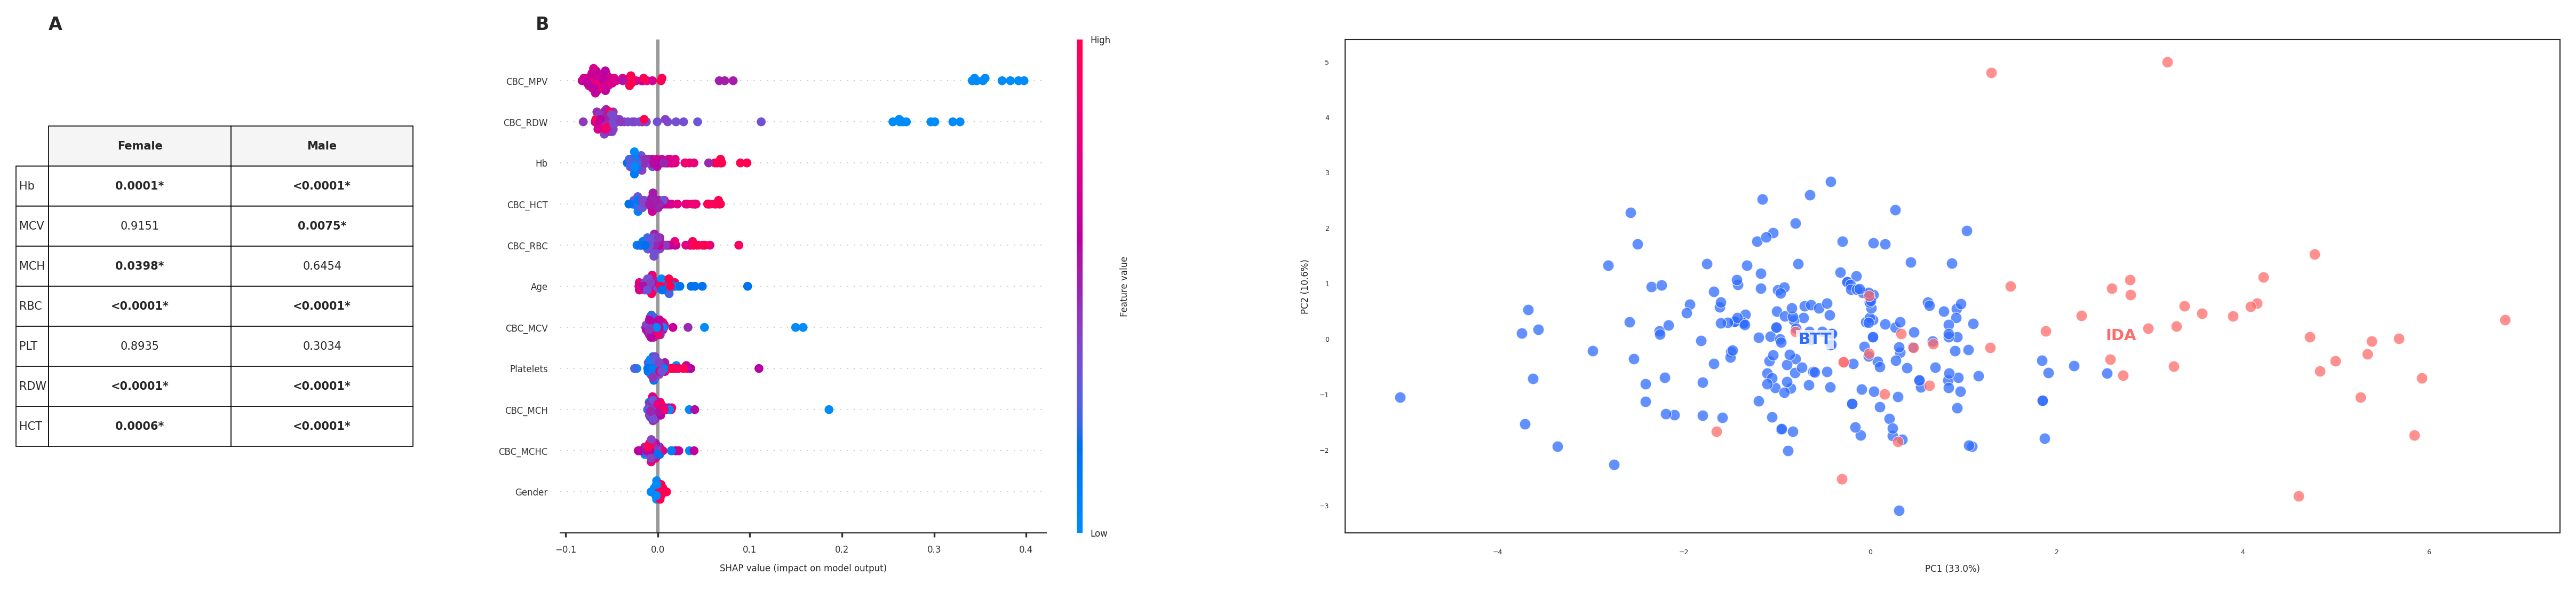

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ============================================================
# STYLE
# ============================================================

BLUE = "#2F6BFF"
RED = "#FF6B6B"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 4,
    "axes.labelsize": 4,
    "xtick.labelsize": 3,
    "ytick.labelsize": 3,
    "axes.linewidth": 0.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# ============================================================
# DATA
# ============================================================

df = dataframes["IDA_BTT_df"].copy()

df = df.drop(columns=["ID", "pname"], errors="ignore")
df = df.dropna()

X = df.drop(columns=["Class"])
y = df["Class"]

# ============================================================
# RANDOM FOREST + SHAP
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values[:, :, 1]

# ============================================================
# PCA
# ============================================================

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Class": y.values
})

# ============================================================
# PANEL A TABLE
# ============================================================

table_df = pd.DataFrame(
    {
        "Female": [
            "0.0001*",
            "0.9151",
            "0.0398*",
            "<0.0001*",
            "0.8935",
            "<0.0001*",
            "0.0006*"
        ],
        "Male": [
            "<0.0001*",
            "0.0075*",
            "0.6454",
            "<0.0001*",
            "0.3034",
            "<0.0001*",
            "<0.0001*"
        ]
    },
    index=[
        "Hb",
        "MCV",
        "MCH",
        "RBC",
        "PLT",
        "RDW",
        "HCT"
    ]
)

fig = plt.figure(
    figsize=(20, 4)
)

gs = fig.add_gridspec(
    1,
    3,
    width_ratios=[1.0, 2.0, 4.0],
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0])

ax1.axis("off")

tbl = ax1.table(
    cellText=table_df.values,
    rowLabels=table_df.index,
    colLabels=table_df.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(5)
tbl.scale(1.2, 1.5)

for (r, c), cell in tbl.get_celld().items():

    cell.set_edgecolor("black")
    cell.set_linewidth(0.4)

    if r == 0:
        cell.set_facecolor("#F5F5F5")
        cell.set_text_props(weight="bold")

    if "*" in cell.get_text().get_text():
        cell.set_text_props(weight="bold")

ax1.text(
    -0.10,
    1.02,
    "A",
    transform=ax1.transAxes,
    fontsize=8,
    fontweight="bold"
)

# ============================================================
# PANEL B
# ============================================================
ax2 = fig.add_subplot(gs[1])

plt.sca(ax2)

shap.summary_plot(
    sv,
    X_test,
    plot_type="dot",
    max_display=len(X.columns),
    show=False
)

# get shap axis
ax2 = plt.gca()

# make feature names larger
for label in ax2.get_yticklabels():
    label.set_fontsize(4)

# x-axis tick labels
for label in ax2.get_xticklabels():
    label.set_fontsize(3)

# axis labels
ax2.set_xlabel(
    ax2.get_xlabel(),
    fontsize=4
)

ax2.set_ylabel(
    ax2.get_ylabel(),
    fontsize=4
)

ax2.tick_params(
    axis="both",
    length=2
)

ax2.text(
    -0.05,
    1.02,
    "B",
    transform=ax2.transAxes,
    fontsize=8,
    fontweight="bold"
)
ax2 = plt.gca()

# feature names
for label in ax2.get_yticklabels():
    label.set_fontsize(4)

# SHAP value axis
for label in ax2.get_xticklabels():
    label.set_fontsize(4)

ax2.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=4
)

# colorbar
cbar = plt.gcf().axes[-1]

cbar.tick_params(labelsize=4)

cbar.set_ylabel(
    "Feature value",
    fontsize=4,
    rotation=90,
    labelpad=4
)

ax3 = fig.add_subplot(gs[2])

colors = {
    0: BLUE,
    1: RED
}

for cls in sorted(pca_df["Class"].unique()):

    subset = pca_df[
        pca_df["Class"] == cls
    ]

    ax3.scatter(
        subset["PC1"],
        subset["PC2"],
        s=25,
        color=colors[cls],
        alpha=0.75,
        edgecolors="white",
        linewidths=0.3
    )

# label class centroids
for cls in sorted(pca_df["Class"].unique()):

    subset = pca_df[
        pca_df["Class"] == cls
    ]

    x_center = subset["PC1"].mean()
    y_center = subset["PC2"].mean()

    if cls == 0:
        label = "BTT"
        color = BLUE
    else:
        label = "IDA"
        color = RED

    ax3.text(
        x_center,
        y_center,
        label,
        fontsize=7,
        fontweight="bold",
        color=color,
        ha="center",
        va="center",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.8,
            pad=1
        )
    )

ax3.set_xlabel(
    f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)",
    fontsize=4
)

ax3.set_ylabel(
    f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)",
    fontsize=4
)


ax3.legend(
    frameon=False,
    fontsize=5,
    loc="upper right"
)

fig.set_size_inches(20, 4)
plt.savefig(
    "Figure2_IDA_BTT.png",
    dpi=1200,
    bbox_inches="tight"
)

plt.savefig(
    "Figure2_IDA_BTT.pdf",
    dpi=1200,
    bbox_inches="tight"
)

plt.show()